## Entregáveis do Projeto

- **Dashboard interativo (Tableau Public):** [Visualizar dashboard](https://public.tableau.com/views/CallMeMaybeOperatorPerformanceAnalysis/CallMeMaybeOperatorPerformance?:language=en-US&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link)
- **Apresentação final:** [Abrir apresentação](https://docs.google.com/presentation/d/1V2OpDKnY3KgdMZhGd_GLhCgZx1PnpsEK/edit?usp=drive_link&ouid=107642534024121673319&rtpof=true&sd=true)

# Decomposicao do Projeto - CallMeMaybe 

## 1. Problema de Negocio
Um operador pode ser considerado potencialmente ineficiente quando:

- Perde muitas chamadas recebidas, tanto internas quanto externas;

- Apresenta um tempo de espera elevado nas chamadas recebidas;

- Realiza poucas chamadas de saída, quando essa atividade faz parte de suas responsabilidades.

O objetivo do projeto é analisar os dados disponíveis e identificar operadores que possam apresentar baixo desempenho de acordo com esses indicadores.


<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Boa reformulação do problema com suas próprias palavras, deixando claros os três sinais de ineficiência (chamadas perdidas, tempo de espera e poucas chamadas de saída).
</div>

<div class="alert alert-block alert-warning">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Vale acrescentar por que resolver esse problema importa para a CallMeMaybe: operadores ineficientes afetam a satisfação dos clientes da empresa (que pagam pelo serviço de telefonia virtual) e podem gerar cancelamentos. Uma frase sobre o contexto desse tipo de serviço também ajuda a mostrar o valor da análise.
</div>

## 2. Objetivo da Analise

O principal objetivo é identificar operadores pontencialmente ineficientes com base em seus indicadores de desempenho. 

A analise sera focada em: 

- Numeros de chamadas recebidas;
- Numeros de chamadas recebidas perdidas;
- Percentual de chamadas recebidas perdidas;
- Tempo medio de espera nas chamadas recebidas;
- Numeros de chamadas de saida;
- Diferencas de desempenho entre os operadores.

Tambem sera realizado testes de hipoteses para verificar se existem diferencas estatisticamente significativas entre os grupos relevantes.

## 3. Preparacao dos Dados

Primeiro, os dados serao carregados e analisados para verificar sua integridade. 

As etapas incluem:

- Carregar os datasets;
- Verificar as primeiras linhas dos dados;
- Verificar os numeros de linhas e colunas;
- Verificar os tipos de dados;
- Identificar valores ausentes;
- Identificar valores duplicados;
- Verificar valores incorretos ou inconsistentes;
- Converter as colunas de data para o tipo correto;
- Verificar os valores unicos das principais variaveis categoricas;
- E por ultimo, preparar os dados para analise. 

<div class="alert alert-block alert-warning">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

A lista de etapas de preparação está bem pensada. Uma sugestão para deixar o plano mais concreto: já carregar as tabelas neste notebook e registrar o volume (linhas, colunas e quais tabelas existem), a qualidade (valores ausentes, duplicados e tipos de dados que precisarão de ajuste) e um resumo estatístico das principais variáveis.

Esse diagnóstico ajuda a antecipar decisões do restante do plano, como tratar ausentes em `operator_id` ou como calcular o tempo de espera, e vai adiantar o trabalho da próxima etapa.
</div>

## 4. Analise Exploratoria de Dados - EDA

Apos a etapa de preparacao, sera realizada uma analise exploratoria para entender o comportamento das chamadas e dos operadores. 

Analise das chamadas: 

- Numero total das chamadas;
- Chamadas recebidas e de saida;
- Chamadas internas e externas;
- Chamadas perdidas;
- Duracao das chamadas e o total;
- Comportamento das chamadas ao longo do tempo.

Analise dos operadores que serao analisados individualmente:

- Numero total das chamadas;
- Numero de chamadas recebidas;
- Numero de chamadas recebidas perdidas;
- Percentual de chamadas recebidas perdidas;
- Tempo medio de espera;
- Numero de chamadas de saida.


## 5. Indicadores de Desempenho

Com base no problema de negocio, serao criados indicadores para comparar o desempenho dos operadores.

- Sera calculado o percentual de chamadas recebidas que foram perdidas:
  Taxa de chamadas perdidas = chamadas recebidas perdidas / total de chamadas recebidas
  Esse indicador permitira identificar operadores que perdem uma proporcao elevada das chamadas recebidas.
  
- O tempo de espera sera calculado utilizando:
  Tempo de espera = duracao total da chamada - duracao da chamada
  Depois podemos calcular o tempo medio de espera das chamadas recebidas para cada operador.
  O foco desse indicador é identificar operadores associados a tempo de espera mais elevados.

- o numero de chamada de saida sera calculado por cada operador, sendo utilizado para avaliar operadores que possuem responsabilidades relacionadas as chamadas de saida.

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Indicadores bem definidos, com fórmulas e ligados diretamente ao problema de negócio. A fórmula do tempo de espera (duração total menos duração da chamada) está correta.
</div>

## 6. Identificacao de operadores potencialmente ineficientes

Serao investigados principalmente os operadores que apresentam uma combinacao: 

- Alta taxa de chamadas recebidas perdidas;
- Alto tempo medio de espera;
- Baixo numeros de chamadas de saida, quando aplicavel.

Os limites utilizados para identificar possiveis operadores ineficientes serao definidos apos analisar a distribuicao de dados. 

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Boa ideia combinar os três indicadores para identificar a ineficiência, em vez de olhar cada um isoladamente.
</div>

<div class="alert alert-block alert-warning">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Vale adiantar como os limites serão definidos (por exemplo, usando percentis da distribuição, como os 10% piores em cada indicador) e como tratar operadores com poucas chamadas, que podem ter taxas extremas só por falta de volume.
</div>

## 7. Testes de Hipoteses

- Serao formuladas hipoteses para investigar se existe diferencas estatisticamente significativas no tempo medio de espera entre os grupos analisados, sendo H₀ (Hipotese nula - Não existe diferença estatisticamente significativa no tempo médio de espera entre os grupos analisados) e H₁ (Hipotese alternativa - Existe diferença estatisticamente significativa no tempo médio de espera entre os grupos analisados.)

- Serao formuladas hipoteses para investigar se existe diferencas estatisticamente significativas na quantidade de chamadas realizadas entre os grupos de operadores analisados, sendo H₀ (Hipotese nula - Não existe diferença estatisticamente significativa na quantidade de chamadas entre os grupos analisados) e H₁ (Hipotese alternativa - Existe diferença estatisticamente significativa na quantidade de chamadas entre os grupos analisados).

O teste estatístico adequado será escolhido após a análise da distribuição e das características dos dados.


<div class="alert alert-block alert-warning">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

As hipóteses estão no formato certo (H₀ e H₁), mas os "grupos analisados" ainda não estão definidos: comparar o tempo de espera entre quais grupos? Por exemplo, operadores classificados como ineficientes contra os demais, chamadas internas contra externas, ou clientes de planos tarifários diferentes. Vale deixar claro os grupos comparados e a variável medida em cada hipótese, para que ela possa ser testada diretamente com os dados.

Como sugestão, inclua também uma terceira hipótese, por exemplo sobre a taxa de chamadas perdidas.
</div>

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Boa visão do que a análise vai entregar ao final, incluindo recomendações para os supervisores.
</div>

<div class="alert alert-block alert-warning">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Para completar o plano, vale incluir:

- quem são os interessados nos resultados (por exemplo, supervisores e gestão da operação) e por que cada um é relevante;
- as atividades de comunicação (apresentação, dashboard);
- uma estimativa de tempo para cada etapa.
</div>

## Descrição dos Dados

Os conjuntos de dados contêm informações sobre o uso do serviço de telefonia virtual **CallMeMaybe**.

Os clientes da empresa são **organizações que precisam gerenciar grandes volumes de chamadas** — tanto recebidas quanto realizadas por diversos operadores.

Os operadores também podem fazer **chamadas internas** entre si, por meio da própria rede da CallMeMaybe.

O dataset compactado **`telecom_dataset_us.csv`** contém as seguintes colunas:

- **`user_id`**: ID da conta do cliente
- **`date`**: data em que as estatísticas foram coletadas
- **`direction`**: “direção” da chamada (`out` para chamadas de **saída**, `in` para chamadas recebidas)
- **`internal`**: indica se a chamada foi **interna** (entre operadores de um mesmo cliente)
- **`operator_id`**: identificador do operador
- **`is_missed_call`**: indica se foi uma **chamada perdida**
- **`calls_count`**: número de chamadas
- **`call_duration`**: duração da chamada (sem incluir o tempo de espera)
- **`total_call_duration`**: duração total da chamada (incluindo o tempo de espera)

---

O conjunto de dados **`telecom_clients_us.csv`** contém as seguintes colunas:

- **`user_id`**: ID do cliente
- **`tariff_plan`**: plano tarifário atual do cliente
- **`date_start`**: data de registro do cliente

In [1]:
import pandas as pd 
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from scipy import stats as st
from scipy.stats import spearmanr
from scipy.stats import mannwhitneyu

## Preparacao dos Dados

In [2]:
df_telecom_clients = pd.read_csv('../data/telecom_clients.csv')
df_telecom_dataset_new = pd.read_csv('../data/telecom_dataset_new.csv')

In [3]:
df_telecom_clients.head()

,user_id,tariff_plan,date_start
0,166713,A,2019-08-15
1,166901,A,2019-08-23
2,168527,A,2019-10-29
3,167097,A,2019-09-01
4,168193,A,2019-10-16


In [4]:
df_telecom_dataset_new.head()

,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
0,166377,2019-08-04 00:00:00+03:00,in,False,NaN,True,2,0,4
1,166377,2019-08-05 00:00:00+03:00,out,True,880022.0,True,3,0,5
2,166377,2019-08-05 00:00:00+03:00,out,True,880020.0,True,1,0,1
3,166377,2019-08-05 00:00:00+03:00,out,True,880020.0,False,1,10,18
4,166377,2019-08-05 00:00:00+03:00,out,False,880022.0,True,3,0,25


In [5]:
df_telecom_clients.info()

<class 'pandas.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   user_id      732 non-null    int64
 1   tariff_plan  732 non-null    str  
 2   date_start   732 non-null    str  
dtypes: int64(1), str(2)
memory usage: 17.3 KB


In [6]:
df_telecom_dataset_new.info()

<class 'pandas.DataFrame'>
RangeIndex: 53902 entries, 0 to 53901
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_id              53902 non-null  int64  
 1   date                 53902 non-null  str    
 2   direction            53902 non-null  str    
 3   internal             53785 non-null  object 
 4   operator_id          45730 non-null  float64
 5   is_missed_call       53902 non-null  bool   
 6   calls_count          53902 non-null  int64  
 7   call_duration        53902 non-null  int64  
 8   total_call_duration  53902 non-null  int64  
dtypes: bool(1), float64(1), int64(4), object(1), str(2)
memory usage: 3.3+ MB


In [7]:
df_telecom_clients['date_start'] = pd.to_datetime(df_telecom_clients['date_start'])
df_telecom_dataset_new['date'] = pd.to_datetime(df_telecom_dataset_new['date'])

In [8]:
df_telecom_clients.info()
df_telecom_dataset_new.info()

<class 'pandas.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   user_id      732 non-null    int64         
 1   tariff_plan  732 non-null    str           
 2   date_start   732 non-null    datetime64[us]
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 17.3 KB
<class 'pandas.DataFrame'>
RangeIndex: 53902 entries, 0 to 53901
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype                    
---  ------               --------------  -----                    
 0   user_id              53902 non-null  int64                    
 1   date                 53902 non-null  datetime64[us, UTC+03:00]
 2   direction            53902 non-null  str                      
 3   internal             53785 non-null  object                   
 4   operator_id          45730 non-null  float64                  
 5   is_missed_call    

In [9]:
df_telecom_dataset_new['internal'].value_counts(dropna=False)

internal
False    47621
True      6164
NaN        117
Name: count, dtype: int64

In [10]:
df_telecom_dataset_new['internal'] = (
    df_telecom_dataset_new['internal'].astype('boolean')
)
df_telecom_dataset_new['internal'].dtype

BooleanDtype

In [11]:
df_telecom_dataset_new['internal'].value_counts(dropna=False)

internal
False    47621
True      6164
<NA>       117
Name: count, dtype: Int64

In [12]:
df_telecom_dataset_new['operator_id'].dropna().mod(1).value_counts()

operator_id
0.0    45730
Name: count, dtype: int64

In [13]:
df_telecom_dataset_new['operator_id'] = (
    df_telecom_dataset_new['operator_id'].astype('Int64')
)
df_telecom_dataset_new['operator_id'].dtype
df_telecom_dataset_new['operator_id'].isna().sum()

np.int64(8172)

### Conversao e adequacao dos tipos de dados
- A coluna `date` estava inicialmente como texto (str). Ela foi convertida para o tipo datetime, permitindo realizar analises temporais.
---
- A coluna `internal` estava inicialmente como object e continha valores True, False e valores ausentes. Apos verificar os valores existentes, ela foi convertida para o tipo anulavel boolean do pandas, preservando os valores ausentes sem atribuir classificacoes arbitrarias.
---
- A coluna `operator_id` estava como float devido a presenca de valores ausentes. A verificacao dos 45.730 valores nulos confirmou que todos eram numeros inteiros, sem casas decimais. Por isso, a coluna foi convertida para o tipo anulavel Int64, que permite representar identificadores inteiros e manter os valores ausentes. 

### Verificacao de consistencia

In [14]:
df_telecom_dataset_new[
    ['calls_count', 'call_duration', 'total_call_duration']
].describe()

,calls_count,call_duration,total_call_duration
count,53902.000000,53902.000000,53902.000000
mean,16.451245,866.684427,1157.133297
std,62.917170,3731.791202,4403.468763
min,1.000000,0.000000,0.000000
25%,1.000000,0.000000,47.000000
50%,4.000000,38.000000,210.000000
75%,12.000000,572.000000,902.000000
max,4817.000000,144395.000000,166155.000000


In [15]:
consistency_check = pd.Series({
    'calls_count <= 0': (df_telecom_dataset_new['calls_count'] <= 0).sum(),
    'call_duration < 0': (df_telecom_dataset_new['call_duration'] < 0).sum(),
    'total_call_duration < 0': (df_telecom_dataset_new['total_call_duration'] < 0).sum(),
    'total_call_duration < call_duration': (
        df_telecom_dataset_new['total_call_duration'] < df_telecom_dataset_new['call_duration']
    ).sum()
})

consistency_check

calls_count <= 0                       0
call_duration < 0                      0
total_call_duration < 0                0
total_call_duration < call_duration    0
dtype: int64

### Verificacao de consistencia das contagens e duracoes
- Foram realizadas quatro verificacoes de consistencia na base de chamadas, contagens menores ou iguais a zero, duracoes de conversa negativas, duracoes totais negativas e registros em que a duracao total fosse inferior a duracao da conversa. 
---
- Nenhum registro apresentou essas inconsistencias. A coluna `calls_count` contem valores positivos, as duracoes nao apresentam valores negativos e a duracao total e sempre maior ou igual a duracao da conversa. 
---
- Agora vamos investigar os valores extremos que apareceram em `calls_count`(4.817), `call_duration`(144.395) e `total_call_duration`(166.155).

In [16]:
df_telecom_dataset_new.nlargest(10, 'calls_count')[
    [
        'user_id',
        'date',
        'direction',
        'operator_id',
        'is_missed_call',
        'calls_count',
        'call_duration',
        'total_call_duration'
    ]
]

,user_id,date,direction,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
40733,167827,2019-11-11 00:00:00+03:00,out,929428,True,4817,0,5529
40671,167827,2019-10-31 00:00:00+03:00,out,929428,True,2614,0,45312
37070,167626,2019-10-07 00:00:00+03:00,in,<NA>,True,2168,0,2361
37102,167626,2019-10-08 00:00:00+03:00,in,<NA>,True,1917,0,2044
37553,167626,2019-10-15 00:00:00+03:00,in,<NA>,True,1914,0,2063
37308,167626,2019-10-11 00:00:00+03:00,in,<NA>,True,1705,0,2455
37343,167626,2019-10-11 00:00:00+03:00,in,<NA>,True,1705,0,2455
50837,168252,2019-11-25 00:00:00+03:00,in,<NA>,True,1679,0,42251
36913,167626,2019-10-04 00:00:00+03:00,in,<NA>,True,1641,0,1210
50888,168252,2019-11-26 00:00:00+03:00,in,<NA>,True,1590,0,42667


In [17]:
df_telecom_dataset_new[
    df_telecom_dataset_new['calls_count'] >= 1500
].duplicated(keep=False).sum()

np.int64(2)

In [18]:
high_calls = df_telecom_dataset_new[
    df_telecom_dataset_new['calls_count'] >= 1500
]
high_calls[
    high_calls.duplicated(keep=False)
].sort_values('calls_count', ascending=False)

,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
37308,167626,2019-10-11 00:00:00+03:00,in,False,<NA>,True,1705,0,2455
37343,167626,2019-10-11 00:00:00+03:00,in,False,<NA>,True,1705,0,2455


In [19]:
df_telecom_dataset_new[
    df_telecom_dataset_new['calls_count'] >= 1500
].groupby([
    'direction', 'is_missed_call'],
    dropna=False
).agg(
    register_total = ('user_id', 'size'),
    calls_total = ('calls_count', 'sum'),
    max_calls_count = ('calls_count', 'max'),
)

,,register_total,calls_total,max_calls_count
direction,is_missed_call,,,
in,True,8,14319,2168
out,True,4,10493,4817


### Investigacao de valores extremos em calls_count
- A analise dos dez maiores valores de `calls_count` identificou registros com contagens elevadas de chamadas. Para investigar esses valores, selecionamos os registros com pelo menos 1500 chamadas. 
---
- Foram encontrados 12 registros nessa condicao, todos classificados como chamadas perdidas. Oito registros correspondem a chamadas recebidas, totalizando 14.319 chamadas, e quatro correspondem a chamadas efetuadas, totalizado 10.493 chamadas. A maior contagem individual foi de 4.817 chamadas. 
---
- Como a base contem registros que podem representar multiplas chamadas agregadas, valores elevados nao foram considerados erros automaticamente. Eles sera preservados, e os resultados serao interpretados considerando a estrutura agregada dos dados. 

### Investigacao de valores nulos

In [20]:
df_telecom_dataset_new.groupby(
    ['direction', 'is_missed_call'],
    dropna=False
).agg(
    register_total = ('user_id', 'size'),
    operator_missing = ('operator_id', lambda s: s.isna().sum())
)

register_total  operator_missing
direction is_missed_call                                  
in        False                    13342                73
          True                      8643              7899
out       False                    16992                49
          True                     14925               151

In [21]:
df_telecom_dataset_new.groupby('direction').agg(
    register_total = ('user_id', 'size'),
    operator_missing = ('operator_id', 'count')
).assign(
    operator_absent = lambda df:
        df['register_total'] - df['operator_missing']
)

,register_total,operator_missing,operator_absent
direction,,,
in,21985,14013,7972
out,31917,31717,200


In [22]:
missing_values = pd.DataFrame(
    {
    'missing_count': df_telecom_dataset_new.isna().sum(),
    'missing_percentage': (
        df_telecom_dataset_new.isna().mean() * 100
    ).round(2)
})
missing_values.sort_values(by='missing_count', ascending=False)

,missing_count,missing_percentage
operator_id,8172,15.16
internal,117,0.22
user_id,0,0.00
date,0,0.00
direction,0,0.00
is_missed_call,0,0.00
calls_count,0,0.00
call_duration,0,0.00
total_call_duration,0,0.00


In [23]:
df_telecom_dataset_new[
    df_telecom_dataset_new['internal'].isna()
].groupby(
    ['direction', 'is_missed_call'],
    dropna=False
).agg(
    register_total = ('user_id', 'size'),
    calls_total = ('calls_count', 'sum')
)

register_total  calls_total
direction is_missed_call                             
in        False                       59           64
          True                        56          164
out       True                         2            6

### Analise de valores ausentes
- A analise identificou 8.172 valores ausentes na coluna `operator_id`, correspondentes a 15,16% dos registros, e 117 valores ausentes na coluna internal, equivalentes a 0,22% da base original.
---
- A ausencia de `operator_id` esta concentrada nas chamadas recebidas, principalmente naquelas classificadas como perdidas. Como nao ha informacoes suficientes esses valores nao serao preenchidos. Os registros serao preservados na analise geral e nao serao utilizados nos indicadores que dependem da identificacao individual do operador. 
---
- O valores ausentes em internal representam 234 chamadas, de acordo com a soma da coluna `calls_count`. 
---
- A analise por categoria mostrou que os valores ausentes estao presentes em chamadas recebidas tanto perdidas quanto nao perdidas, e em dois registros de chamadas efetuadas perdidas. Nao foram encontrados valores ausentes nessa coluna entre as chamadas efetuadas nao perdidas. 

### Investigacao de duplicatas

In [24]:
duplicate_count = df_telecom_clients.duplicated().sum()

duplicate_percentage = duplicate_count / len(df_telecom_clients) * 100

print("Duplicatas:", duplicate_count)
print("Percentual:", duplicate_percentage)

Duplicatas: 0
Percentual: 0.0


In [25]:
df_telecom_clients[df_telecom_clients.duplicated(keep=False)].head(10)

,user_id,tariff_plan,date_start


In [26]:
duplicate_clients = (
    df_telecom_clients['user_id']
    .duplicated()
    .sum()
)
print(f"Number of duplicate user_id in df_telecom_clients: {duplicate_clients}")
print(f"Number of duplicate rows considering user_id: "
      f"{df_telecom_clients.duplicated(subset=['user_id'], keep=False).sum()}")
print(f"Number of unique users in df_telecom_clients: {df_telecom_clients['user_id'].nunique()}")
print(f"Total number of lines in df_telecom_clients: {len(df_telecom_clients)}")

Number of duplicate user_id in df_telecom_clients: 0
Number of duplicate rows considering user_id: 0
Number of unique users in df_telecom_clients: 732
Total number of lines in df_telecom_clients: 732


In [27]:
duplicate_count_dataset = df_telecom_dataset_new.duplicated().sum()

duplicate_percentage_dataset = duplicate_count_dataset / len(df_telecom_dataset_new) * 100

print("Duplicatas:", duplicate_count_dataset)
print("Percentual:", duplicate_percentage_dataset)

Duplicatas: 4900
Percentual: 9.090571778412675


- 4,900 duplicate records were found, representing approximately 9.09% of the database.

In [28]:
df_telecom_dataset_new[df_telecom_dataset_new.duplicated(keep=False)].head(10)

,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
6,166377,2019-08-05 00:00:00+03:00,out,False,880020,True,8,0,50
8,166377,2019-08-05 00:00:00+03:00,out,False,880020,True,8,0,50
27,166377,2019-08-12 00:00:00+03:00,in,False,<NA>,True,2,0,34
28,166377,2019-08-12 00:00:00+03:00,in,False,<NA>,True,2,0,34
38,166377,2019-08-14 00:00:00+03:00,in,False,<NA>,True,1,0,3
43,166377,2019-08-14 00:00:00+03:00,out,False,880026,False,10,1567,1654
44,166377,2019-08-14 00:00:00+03:00,out,False,880026,False,10,1567,1654
45,166377,2019-08-14 00:00:00+03:00,in,False,<NA>,True,1,0,3
46,166377,2019-08-15 00:00:00+03:00,out,False,880026,False,11,1413,1473
51,166377,2019-08-15 00:00:00+03:00,out,False,880026,False,11,1413,1473


In [29]:
df_without_duplicates = df_telecom_dataset_new.drop_duplicates()

print('Original records: ', len(df_telecom_dataset_new))

print('Records without duplicates: ', len(df_without_duplicates))

missed_calls_before = df_telecom_dataset_new.loc[
    df_telecom_dataset_new['is_missed_call'] == True,
        'calls_count'
    ].sum()



missed_calls_after = df_without_duplicates.loc[
    df_without_duplicates['is_missed_call'] == True,
        'calls_count'
    ].sum()

print("Missed calls before:", missed_calls_before)
print("Missed calls after:", missed_calls_after)
print("Difference:", missed_calls_before - missed_calls_after)

Original records:  53902
Records without duplicates:  49002
Missed calls before: 412305
Missed calls after: 375918
Difference: 36387


- O total de chamadas perdidas diminuiu 36.387, aproximadamente 8,83% do total original de chamadas perdidas, sendo diferencas entre os dois cenarios calculados. Sendo significativo para a nossa analise: a presenca dessas duplicatas altera materialmente uma metrica importante do projeto. 

In [30]:
duplicate_rows = df_telecom_dataset_new[
    df_telecom_dataset_new.duplicated(keep=False)
]

duplicate_rows.groupby('direction').agg(
    duplicate_records=('user_id', 'size'),
    missed_calls=('calls_count', 'sum'),
    operators=('operator_id', 'nunique')
)

missed_by_operator_before = (
    df_telecom_dataset_new[
        (df_telecom_dataset_new['direction'] == 'in') &
        (df_telecom_dataset_new['is_missed_call'] == True)
    ]
    .groupby('operator_id')['calls_count']
    .sum()
)

missed_by_operator_after = (
    df_without_duplicates[
        (df_without_duplicates['direction'] == 'in') &
        (df_without_duplicates['is_missed_call'] == True)
    ]
    .groupby('operator_id')['calls_count']
    .sum()
)

comparison = pd.concat([
    missed_by_operator_before.rename('before'),
    missed_by_operator_after.rename('after')
], axis=1).fillna(0)

comparison['difference'] = comparison['before'] - comparison['after']

comparison.sort_values(by='difference', ascending=False).head(10)

,before,after,difference
operator_id,,,
944216,32,24,8
944226,38,30,8
885876,24,20,4
937860,8,5,3
913942,55,52,3
944220,21,18,3
951508,24,21,3
940658,13,10,3
919206,12,9,3


In [31]:
comparison['percentage_difference'] = (
    comparison['difference']
    .div(comparison['before'].replace(0, float('nan')))
    .mul(100)
)

print('Largest absolute difference:', comparison['difference'].max())

print('\nAffected operators:')
print((comparison['difference'] > 0).sum())
print('\nLargest percentage difference:', comparison['percentage_difference'].max())

comparison['rank_before'] = (
    comparison['before']
    .rank(method='min', ascending=False)
)
comparison['rank_after'] = (
    comparison['after']
    .rank(method='min', ascending=False)
)
comparison['rank_change'] = (
comparison['rank_before'] - comparison['rank_after']
)

print('\nLargest rank change:', comparison['rank_change'].abs().max())

Largest absolute difference: 8

Affected operators:
46

Largest percentage difference: 50.0

Largest rank change: 36.0


In [32]:
comparison.sort_values(by='rank_change', key=abs, ascending=False)[
    [
    'before',
    'after',
    'difference',
    'rank_before',
    'rank_after',
    'rank_change'
    ]
].head(10)

,before,after,difference,rank_before,rank_after,rank_change
operator_id,,,,,,
920726,2,1,1,94.0,130.0,-36.0
953464,2,1,1,94.0,130.0,-36.0
919792,2,1,1,94.0,130.0,-36.0
919896,2,1,1,94.0,130.0,-36.0
906294,2,1,1,94.0,130.0,-36.0
905566,2,1,1,94.0,130.0,-36.0
937812,2,1,1,94.0,130.0,-36.0
934430,2,1,1,94.0,130.0,-36.0
911142,3,2,1,68.0,90.0,-22.0


In [33]:
print("Records original: ", len(df_telecom_dataset_new))

print("Exact duplicates: ", df_telecom_dataset_new.duplicated().sum())

print("Records after removing duplicates: ", len(df_telecom_dataset_new.drop_duplicates()))

Records original:  53902
Exact duplicates:  4900
Records after removing duplicates:  49002


### Tratamento de registros duplicados

- Durante a analise exploratoria, foram identificados 4.900 registros duplicados exatos, correspondentes a aproximadamente 9,09% dos registros originais. A remocao dessas duplicatas reduziu o volume de registros de 53.902 para 49.002 e o total de chamadas perdidas de 412.305 para 375.918, uma diferenca de 36.387 chamadas.
---
- A comparacao por operador mostrou que as maiores mudancas de posicao no ranking ocorreram entre os operadores com poucas chamadas perdidas. Alguns operadores passaram de duas para uma chamada perdida e mudaram 36 posicoes, demonstrando que o ranking e sensivel a pequenas diferencas absolutas.
---
- A identificacao de duplicatas foi realizada considerando todas as colunas disponiveis. Entretanto, os dados nao possuem um identificador unico de chamada que permita confirmar individualmente a origem de cada registro duplicado. Portanto, nao e possivel afirmar que todas as duplicatas identificadas resultam de uma duplicacao indevida.
---
- Portanto para a analise principal, serao utilizados os registros sem duplicatas exatas, mantendo-se a base original preservada. Essa decisao se basea na possibilidade de duplicacao indevida, mas reconhece que os dados disponiveis nao permitem confirmar individualmente a origem de cada registro duplicado. 

In [34]:
df_original = df_telecom_dataset_new

df_deduplicated = df_telecom_dataset_new.drop_duplicates()

comparison_missed_calls = pd.DataFrame({
    'original': [
        df_original.loc[
            df_original['is_missed_call'], 'calls_count'
        ].sum()
    ],
    'deduplicated': [
        df_deduplicated.loc[
            df_deduplicated['is_missed_call'], 'calls_count'
        ].sum()
    ]
}, index=['missed_calls_total'])

comparison_missed_calls['difference'] = (
    comparison_missed_calls['original'] - comparison_missed_calls['deduplicated']
)

comparison_missed_calls

,original,deduplicated,difference
missed_calls_total,412305,375918,36387


- A comparacao dos indicadores antes e depois da remocao das duplicatas mostrou uma reducao de 412.305 para 375.918 chamadas perdidas, uma diferenca de 36.387 chamadas, equivalente a aproximadamente 8,83% do total original. Esse resultado demonstra que o tratamento de duplicatas tem impacto relevante nos indicadore agregados. Entretanto, como nao ha um identificador unico de chamada para confirmar a origem dos registros, essa diferenca deve ser interpretada como o impacto da remocao, e nao como uma comprovacao do numero de chamadas efetivamente duplicadas.

In [35]:
df_telecom_analysis = df_telecom_dataset_new.drop_duplicates().copy()
print("Registros para análise:", len(df_telecom_analysis))
print("Duplicatas restantes:", df_telecom_analysis.duplicated().sum())

Registros para análise: 49002
Duplicatas restantes: 0


# Analise Exploratoria de Dados - EDA

In [36]:
df_incoming = df_telecom_analysis[df_telecom_analysis['direction'] == 'in'].copy()
df_incoming.shape

(20003, 9)

In [37]:
def build_operator_call_metrics(data, direction):
    calls = data.loc[
        (data['direction'] == direction)
        & data['operator_id'].notna()
    ].copy()

    calls['active_calls_count'] = calls['calls_count'].where(
        ~calls['is_missed_call'], 0
    )

    calls['missed_calls_count'] = calls['calls_count'].where(
        calls['is_missed_call'], 0
    )

    metrics = (
        calls.groupby('operator_id')
        .agg(
            register_total=('calls_count', 'size'),
            all_calls=('calls_count', 'sum'),
            active_calls=('active_calls_count', 'sum'),
            missed_calls=('missed_calls_count', 'sum')
        )
    )

    metrics['missed_rate_pct'] = (
        metrics['missed_calls']
        .div(metrics['all_calls'].where(metrics['all_calls'] > 0))
        * 100
    )

    return metrics

#### Calcular chamadas recebidas e perdidas por operador

In [101]:
# df_incoming_by_operator = df_incoming[
#     df_incoming['operator_id'].notna()
# ].copy()

# operator_metrics = df_incoming_by_operator.groupby('operator_id').agg(
#     incoming_calls=('calls_count', 'sum'),
#     missed_calls=(
#         'calls_count',
#         lambda s: s[df_incoming_by_operator.loc[s.index, 'is_missed_call']].sum()
#     )
# )

# operator_metrics['missed_call_rate'] = (
#     operator_metrics['missed_calls'] / operator_metrics['incoming_calls'] * 100
# )

# operator_metrics = operator_metrics.sort_values(by='missed_call_rate', ascending=False)

# operator_metrics.head(10)

operator_metrics = (
    build_operator_call_metrics(
        df_telecom_analysis,
        'in'
    )
    .rename(columns={
        'all_calls': 'incoming_calls',
        'missed_rate_pct': 'missed_call_rate'
    })[
        [
            'incoming_calls',
            'missed_calls',
            'missed_call_rate'
        ]
    ]
    .sort_values(
        'missed_call_rate',
        ascending=False
    )
)

In [99]:
print("Total de operadores:", len(operator_metrics))

display(operator_metrics.head(10))

print(
    "Valores ausentes na taxa:",
    operator_metrics['missed_call_rate'].isna().sum()
)

Total de operadores: 754


,incoming_calls,missed_calls,missed_call_rate,difference_vs_overall_pp
operator_id,,,,
948756,1,1,100.000000,47.270338
904344,4,3,75.000000,22.270338
913886,2,1,50.000000,-2.729662
906392,18,7,38.888889,-13.840773
957922,3,1,33.333333,-19.396329
937432,3,1,33.333333,-19.396329
934098,6,2,33.333333,-19.396329
897872,3,1,33.333333,-19.396329
906412,26,7,26.923077,-25.806585


Valores ausentes na taxa: 0


In [39]:
overall_incoming_calls = df_incoming['calls_count'].sum()

overall_missed_calls = df_incoming.loc[
    df_incoming['is_missed_call'], 'calls_count'
].sum() 

overall_missed_rate = (
    overall_missed_calls / overall_incoming_calls * 100
)

print("Total calls received:", overall_incoming_calls)
print("Total missed calls:", overall_missed_calls)
print("Overall missed call rate: {:.2f}%".format(overall_missed_rate))

Total calls received: 197845
Total missed calls: 104323
Overall missed call rate: 52.73%


#### Comparar os operadores com a taxa geral

In [40]:
operator_metrics['difference_vs_overall_pp'] = (
    operator_metrics['missed_call_rate'] - overall_missed_rate
)

operator_metrics.sort_values(by='difference_vs_overall_pp', ascending=False).head(10)

,incoming_calls,missed_calls,missed_call_rate,difference_vs_overall_pp
operator_id,,,,
948756,1,1,100.000000,47.270338
904344,4,3,75.000000,22.270338
913886,2,1,50.000000,-2.729662
906392,18,7,38.888889,-13.840773
957922,3,1,33.333333,-19.396329
937432,3,1,33.333333,-19.396329
934098,6,2,33.333333,-19.396329
897872,3,1,33.333333,-19.396329
906412,26,7,26.923077,-25.806585


#### Investigar o volume de chamadas por operador

In [41]:
operator_metrics['incoming_calls'].describe()

count     754.000000
mean      124.405836
std       356.450649
min         1.000000
25%         4.000000
50%        17.000000
75%        78.750000
max      4766.000000
Name: incoming_calls, dtype: float64

- Apos a remocao das duplicatas exatas, foi criada uma base de analise com 49.002 registros. A partir dela, foram selecionadas 20.003 linhas correspondentes as chamadas recebidas (direction = in).
---
- Para avaliar o desempenho individual, foram considerados apenas os registros com `operator_id` identificado. Foram calculados o total de chamadas recebidas, o total de chamadas perdidas e a taxa de chamadas perdidas por operador. Esses indicadores utilizam a soma de `calls_count`, pois cada registro pode representar multiplas chamadas. 
---
- A analise inicial mostrou operadores com taxas de chamadas perdidas elevadas, incluindo caso de 100% e 75%. Entretanto, esses percentuais foram calculados sobre volumes muito pequenos, como uma chamada recebida ou quatro chamadas recebidas. Por isso, taxas elevafas isoladamente nao sao suficientes para concluir que um operador apresenta desempenho insatisfatorio. 
---
- A distribuicao do volume de chamadas entre os 754 operadores analisados mostrou uma media de 124,41 chamadas e uma mediana de 17 chamadas por operador. O primeiro quartil foi de 4 chamadas, o terceiro quartil foi de 78,75 chamadas e o maior volume individual foi de 4.766 chamadas. A diferenca entre a media e a mediana indica uma distribuicao assimetrica, com alguns operadores concentrando volumes elevados de chamadas.
---
- Vale destacar que tambem foi calculada uma taxa geral de chamadas recebidas perdidas de 52,73%, considerando todos os registros de chamadas recebidas, inclusive aqueles sem operador identificado. Como os indicadores individuais incluem somente chamadas atribuidas a operadores, essa taxa geral nao deve ser utilizada como referencia direta sem considerar a diferenca entre as populacoes analisadas. 

#### Calcular a taxa de referencia

In [42]:
identified_incoming_calls = (
    operator_metrics['incoming_calls'].sum()
)

identified_missed_calls = (
    operator_metrics['missed_calls'].sum()
)

identified_missed_rate = (
    identified_missed_calls / identified_incoming_calls * 100
)

print("Incoming calls with identified operator:", identified_incoming_calls)

print("Missed calls with identified operator:",identified_missed_calls)

print("Missed call rate with identified operator: {:.2f}%".format(identified_missed_rate))   

Incoming calls with identified operator: 93802
Missed calls with identified operator: 926
Missed call rate with identified operator: 0.99%


In [43]:
df_incoming.groupby(
    [
        df_incoming['operator_id'].notna().rename(
            'operator_identified'
        ),
        'is_missed_call'
    ]
).agg(
    register_total=('user_id', 'size'),
    calls_total=('calls_count', 'sum')
)

register_total  calls_total
operator_identified is_missed_call                             
False               False                       68          646
                    True                      7202       103397
True                False                    12048        92876
                    True                       685          926

In [100]:
incoming_by_id_status = df_incoming.assign(
    operator_identified = df_incoming['operator_id'].notna()
).groupby('operator_identified').apply(
    lambda group: pd.Series({
        'register_total': len(group),
        'calls_total': group['calls_count'].sum(),
        'missed_calls': group.loc[
            group['is_missed_call'], 'calls_count'
        ].sum(),
        'missed_call_rate_pct': (
            group.loc[
                group['is_missed_call'], 'calls_count'
            ].sum()
            / group['calls_count'].sum()
            * 100
        )
    }),
    include_groups=False
)
incoming_by_id_status

,register_total,calls_total,missed_calls,missed_call_rate_pct
operator_identified,,,,
False,7270.0,104043.0,103397.0,99.379103
True,12733.0,93802.0,926.0,0.987186


In [45]:
df_incoming.assign(
    operator_identified=df_incoming['operator_id'].notna()
).groupby(
    ['operator_identified', 'is_missed_call']
).size().unstack(fill_value=0)

is_missed_call,False,True
operator_identified,,
False,68,7202
True,12048,685


In [46]:
df_incoming[df_incoming['operator_id'].isna()].groupby(
    'is_missed_call'
)['calls_count'].agg(
    register_total='count',
    calls_total='sum',
    mean_calls='mean',
    median_calls='median',
    max_calls='max'
)

,register_total,calls_total,mean_calls,median_calls,max_calls
is_missed_call,,,,,
False,68,646,9.500000,2.0,52
True,7202,103397,14.356706,2.0,2168


- Os registros foram separados em dois grupos de acordo com a presença de `operator_id`. Os resultados mostram uma diferença expressiva entre os grupos. Aproximadamente 99,38% do volume de chamadas no grupo sem operador identificado está marcado como perdido, enquanto essa proporção é de aproximadamente 0,99% no grupo com operador identificado. Essa diferença indica uma forte associação entre a ausência de `operator_id` e o status de chamada perdida. Entretanto, os resultados, isoladamente, não permitem estabelecer uma relação causal nem concluir que os operadores identificados apresentam melhor desempenho. Uma hipótese a investigar é que chamadas não atendidas não sejam associadas a um operador específico pelo sistema.
---
- Alem do volume de chamadas, foi analisada a quantidade de registros em cada grupo. No grupo sem operador identificado, aproximadamente 99,1% dos registros estão marcados como perdidos. No grupo com operador identificado, essa proporção é de aproximadamente 5,4%. Essas porcentagens diferem das taxas calculadas anteriormente porque, nesta comparação, o denominador é a quantidade de registros, e não a soma de `calls_count`.
---
- Foi realizada uma análise descritiva de `calls_count` para os registros sem `operator_id`. A diferença entre a média(Nao perdidas - 9,50, Perdidas - 14,36) e a mediana(Nao perdidas - 2, Perdidas - 2) indica uma distribuição assimétrica de `calls_count`, especialmente entre as chamadas perdidas. Alguns registros com volumes elevados aumentam a média, enquanto a mediana permanece em 2. O valor máximo de 2.168 chamadas em um único registro merece investigação adicional. Entretanto, um valor elevado não constitui, por si só, evidência de erro, pois `calls_count` pode representar chamadas agregadas.
---
- Com base nos resultados obtidos até esta etapa, foram definidas as seguintes diretrizes:
    - Manter os registros sem `operator_id` nas métricas gerais de chamadas, pois eles representam parte relevante do volume observado.
    - Não preencher os valores ausentes de `operator_id` com identificadores arbitrarios.
    - Utilizar apenas registros com operador identificado nas analises de desempenho individual, deixando explícita essa limitação.
    - Evitar classificar operadores como ineficientes com base em taxas calculadas sobre volumes muito pequenos.
    - Investigar os registros com valores elevados de `calls_count` antes de decidir se existe algum problema de qualidade.
    - Não atribuir uma causa definitiva à diferença entre os grupos sem evidências adicionais sobre o funcionamento do sistema.
---
- A próxima etapa será investigar os registros com maior `calls_count` entre as chamadas recebidas perdidas sem operador identificado. O objetivo será verificar se existem padrões por usuário e data que ajudem a compreender esses valores elevados.

In [47]:
df_incoming[
    df_incoming['operator_id'].isna()
    & df_incoming['is_missed_call']
].nlargest(10, 'calls_count')[
    [
        'user_id',
        'date',
        'direction',
        'calls_count',
        'call_duration',
        'total_call_duration'
    ]
]

,user_id,date,direction,calls_count,call_duration,total_call_duration
37070,167626,2019-10-07 00:00:00+03:00,in,2168,0,2361
37102,167626,2019-10-08 00:00:00+03:00,in,1917,0,2044
37553,167626,2019-10-15 00:00:00+03:00,in,1914,0,2063
37308,167626,2019-10-11 00:00:00+03:00,in,1705,0,2455
50837,168252,2019-11-25 00:00:00+03:00,in,1679,0,42251
36913,167626,2019-10-04 00:00:00+03:00,in,1641,0,1210
50888,168252,2019-11-26 00:00:00+03:00,in,1590,0,42667
37193,167626,2019-10-09 00:00:00+03:00,in,1432,0,1273
37481,167626,2019-10-14 00:00:00+03:00,in,1411,0,1901
36824,167626,2019-10-03 00:00:00+03:00,in,1311,0,1136


In [48]:
df_incoming = df_incoming.assign(
    avg_total_duration_per_call=(
        df_incoming['total_call_duration']
        / df_incoming['calls_count']
    )
)

df_incoming[
    [
        'user_id',
        'date',
        'calls_count',
        'call_duration',
        'total_call_duration',
        'avg_total_duration_per_call'
    ]
]

,user_id,date,calls_count,call_duration,total_call_duration,avg_total_duration_per_call
0,166377,2019-08-04 00:00:00+03:00,2,0,4,2.000000
7,166377,2019-08-05 00:00:00+03:00,6,0,35,5.833333
9,166377,2019-08-06 00:00:00+03:00,4,0,62,15.500000
17,166377,2019-08-07 00:00:00+03:00,2,0,24,12.000000
26,166377,2019-08-12 00:00:00+03:00,1,407,411,411.000000
...,...,...,...,...,...,...
53889,168603,2019-11-28 00:00:00+03:00,1,0,30,30.000000
53891,168606,2019-11-08 00:00:00+03:00,1,0,7,7.000000
53893,168606,2019-11-08 00:00:00+03:00,6,0,121,20.166667
53894,168606,2019-11-08 00:00:00+03:00,2,686,705,352.500000


In [ ]:
missed_without_operator = df_incoming[
    df_incoming['operator_id'].isna()
    & df_incoming['is_missed_call']
].copy()

missed_without_operator['avg_total_duration_per_call'] = (
    missed_without_operator['total_call_duration']
    / missed_without_operator['calls_count']
)

missed_without_operator['avg_total_duration_per_call'].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
)

count    7202.000000
mean       18.811097
std        21.750507
min         0.000000
50%        14.000000
75%        27.500000
90%        40.950758
95%        52.000000
99%        91.495000
max       465.000000
Name: avg_total_duration_per_call, dtype: float64

In [50]:
missed_without_operator = df_incoming[
    df_incoming['operator_id'].isna()
    & df_incoming['is_missed_call']
].copy()

missed_without_operator['avg_total_duration_per_call'] = (
    missed_without_operator['total_call_duration']
    / missed_without_operator['calls_count']
)

print('Total filtered records:',
      len(missed_without_operator))

print('Missing values ​​in calls_count:',
      missed_without_operator['calls_count'].isna().sum())

print('Missing values in total_call_duration:',
      missed_without_operator['total_call_duration'].isna().sum())

print('Values ​​valid for the average duration:',
      missed_without_operator['avg_total_duration_per_call'].count())

Total filtered records: 7202
Missing values ​​in calls_count: 0
Missing values in total_call_duration: 0
Values ​​valid for the average duration: 7202


In [51]:
missed_without_operator.nlargest(
    10, 'avg_total_duration_per_call'
)[
    [
        'user_id',
        'date',
        'calls_count',
        'call_duration',
        'total_call_duration',
        'avg_total_duration_per_call'
    ]
]

,user_id,date,calls_count,call_duration,total_call_duration,avg_total_duration_per_call
3044,166485,2019-09-22 00:00:00+03:00,1,0,465,465.0
19683,166983,2019-11-28 00:00:00+03:00,1,0,366,366.0
4220,166503,2019-10-27 00:00:00+03:00,1,0,354,354.0
5758,166536,2019-09-05 00:00:00+03:00,1,0,332,332.0
12629,166732,2019-10-30 00:00:00+03:00,2,0,588,294.0
19828,166997,2019-09-10 00:00:00+03:00,2,0,549,274.5
22291,167059,2019-11-01 00:00:00+03:00,1,0,225,225.0
28750,167185,2019-11-23 00:00:00+03:00,2,0,429,214.5
19647,166983,2019-11-26 00:00:00+03:00,2,0,426,213.0
28724,167185,2019-11-15 00:00:00+03:00,1,0,206,206.0


In [52]:
p99_duration = missed_without_operator[
    'avg_total_duration_per_call'
].quantile(0.99)

extreme_duration_records = missed_without_operator[
    missed_without_operator['avg_total_duration_per_call'] 
    > p99_duration
].copy()

print(f'99 percentile limit: {p99_duration:.2f}')
print(f'Records above the P99: {len(extreme_duration_records)}')
print(
    f'Records percentage: '
    f'{len(extreme_duration_records) / len(missed_without_operator) * 100:.2f}%'
)


99 percentile limit: 91.49
Records above the P99: 73
Records percentage: 1.01%


In [53]:
extreme_by_user = (
    extreme_duration_records
    .groupby('user_id')
    .agg(
        register_total=('user_id', 'size'),
        calls_total=('calls_count', 'sum'),
        max_avg_duration=(
            'avg_total_duration_per_call', 'max'
        )
    ).sort_values(
        ['register_total', 'max_avg_duration'],
        ascending=False
    )
)
extreme_by_user.head(10)

,register_total,calls_total,max_avg_duration
user_id,,,
166503,13,35,354.000000
166983,6,17,366.000000
167185,6,9,214.500000
166732,3,7,294.000000
167059,3,3,225.000000
166536,2,3,332.000000
166997,2,3,274.500000
167199,2,2,160.000000
167521,2,28,145.888889


In [54]:
top_recurrent_users = extreme_by_user.head(3).index

extreme_duration_records[
    extreme_duration_records['user_id'].isin(
        top_recurrent_users
    )
].sort_values(
    ['user_id', 'date']
)[
    [
        'user_id',
        'date',
        'calls_count',
        'call_duration',
        'total_call_duration',
        'avg_total_duration_per_call'
    ]
]

,user_id,date,calls_count,call_duration,total_call_duration,avg_total_duration_per_call
4050,166503,2019-09-21 00:00:00+03:00,2,0,218,109.000000
4161,166503,2019-10-13 00:00:00+03:00,4,0,549,137.250000
4180,166503,2019-10-17 00:00:00+03:00,4,0,762,190.500000
4191,166503,2019-10-20 00:00:00+03:00,2,0,314,157.000000
4216,166503,2019-10-25 00:00:00+03:00,4,0,447,111.750000
4218,166503,2019-10-26 00:00:00+03:00,1,0,115,115.000000
4220,166503,2019-10-27 00:00:00+03:00,1,0,354,354.000000
4243,166503,2019-11-03 00:00:00+03:00,2,0,210,105.000000
4252,166503,2019-11-05 00:00:00+03:00,2,0,364,182.000000
4268,166503,2019-11-10 00:00:00+03:00,3,0,338,112.666667


In [55]:
extreme_by_date = (
    extreme_duration_records
    .groupby('date')
    .agg(
        register_total=('user_id', 'size'),
        unique_users=('user_id', 'nunique'),
        calls_total=('calls_count', 'sum'),
        max_avg_duration=(
            'avg_total_duration_per_call', 'max'
        )
    ).sort_values(
        ['register_total', 'max_avg_duration'],
        ascending=False
    )
)

extreme_by_date.head(10)

,register_total,unique_users,calls_total,max_avg_duration
date,,,,
2019-10-25 00:00:00+03:00,5,5,8,141.000000
2019-11-17 00:00:00+03:00,4,4,7,108.000000
2019-10-30 00:00:00+03:00,3,3,4,294.000000
2019-11-26 00:00:00+03:00,3,3,10,213.000000
2019-11-15 00:00:00+03:00,3,3,4,206.000000
2019-11-12 00:00:00+03:00,3,3,7,124.333333
2019-11-24 00:00:00+03:00,3,3,12,120.500000
2019-11-01 00:00:00+03:00,2,2,2,225.000000
2019-11-23 00:00:00+03:00,2,2,3,214.500000


In [56]:
extreme_records_by_date = (
    extreme_duration_records
    .groupby('date')
    .size()
    .sort_values(ascending=False)
)

print('Total number of extreme records:',
      len(extreme_duration_records))

print('Different dates:',
      extreme_duration_records['date'].nunique())

print('Maximum number of extreme records on a given date:',
      extreme_records_by_date.max())

print('\nDistribution of the number of records by date:')
print(extreme_records_by_date.value_counts().sort_index())

Total number of extreme records: 73
Different dates: 47
Maximum number of extreme records on a given date: 5

Distribution of the number of records by date:
1    31
2     9
3     5
4     1
5     1
Name: count, dtype: int64


### Investigacao de valores extremos na duracao media por chamada

- O objetivo era investigar os registros com duracao total media por chamada elevada entre as chamadas recebidas perdidas sem operador identificado `operator_id ausente`, verificando a distribuicao dos valores e a possivel concentracao por usuario e data. A metrica exploratoria foi calculada dividindo `total_call_duration` por `calls_count`.
---
- A analise foi realizada sobre 7.202 registros de chamadas recebidas perdidas sem operador identificado. Estatistica: Media (18,81), Mediana (14,00), Percentil 75 (27,50), Percentil 90 (40,95), Percentil 95 (52,00), Percentil 99 (91,50) e Maximo (465,00).
---
- O limite calculado para o percentil 99 foi de aproximadamente 91,50. Foram identificados 73 registros acima desse limite, correspondendo a aproximadamente 1,01% do grupo analisado. Esse registros foram considerados valores extremos para fins exploratorios, mas nao sigfinica necessariamente que um registro seja invalido. 
---
- A analise por usuario identificou ocorrencias repetidas entre os registros extremos. Os tres usuarios com maior quantidade foram: 166503 (13 registros), 166983 (6 registros) e 167185 (6 registros). Os registros desses usuarios ocorreram em diferentes datas entre setembro e novembro de 2019, indicando que as ocorrencias nao se limitam a um unico dia.
---
- As investigacao por data nos mostraram que os 73 registros extremos foram distribuidos por 47 datas distintas. Os numeros de datas 31 (teve 1 registro), 9 (teve 2 registros), 5 (teve 3 registros), 1 (teve 4 registros) e 1 (teve 5 registros). O maior numero de registros extremos observado em uma unica data foi 5. A distribuicao indica que os registros estao espalhados ao longo do periodo analisado, sem uma concentracao em uma unica data. Apesar disso, alguns usuarios apresentam recorrencia em diferente dias. 

#### Calcular o tempo de espera

In [57]:
df_incoming_wait = df_telecom_analysis[
    df_telecom_analysis['direction'] == 'in'
].copy()

df_incoming_wait['wait_time_total'] = (
    df_incoming_wait['total_call_duration']
    - df_incoming_wait['call_duration']
)

df_incoming_wait['avg_wait_per_call'] = (
    df_incoming_wait['wait_time_total']
    / df_incoming_wait['calls_count']
)

df_incoming_wait[
    [
        'user_id',
        'operator_id',
        'is_missed_call',
        'calls_count',
        'call_duration',
        'total_call_duration',
        'wait_time_total',
        'avg_wait_per_call'
    ]
].head(10)


,user_id,operator_id,is_missed_call,calls_count,call_duration,total_call_duration,wait_time_total,avg_wait_per_call
0,166377,<NA>,True,2,0,4,4,2.000000
7,166377,<NA>,True,6,0,35,35,5.833333
9,166377,<NA>,True,4,0,62,62,15.500000
17,166377,<NA>,True,2,0,24,24,12.000000
26,166377,880028,False,1,407,411,4,4.000000
27,166377,<NA>,True,2,0,34,34,17.000000
30,166377,<NA>,True,7,0,128,128,18.285714
34,166377,880028,False,1,88,102,14,14.000000
37,166377,880026,False,2,197,218,21,10.500000
38,166377,<NA>,True,1,0,3,3,3.000000


In [58]:
print(
    'Negative waiting times:',
    (df_incoming_wait['wait_time_total'] < 0).sum()
)

Negative waiting times: 0


In [59]:
wait_summary = (
    df_incoming_wait
    .groupby('is_missed_call')
    .agg(
        register_total=('calls_count', 'size'),
        calls_total=('calls_count', 'sum'),
        total_wait_time=('wait_time_total', 'sum'),
        median_wait_per_record=('avg_wait_per_call', 'median'),
        p90_wait_per_record=('avg_wait_per_call', 
                             lambda x: x.quantile(0.90)
        ),
            max_wait_per_record=('avg_wait_per_call', 'max')
    )
)

wait_summary['weighted_avg_wait_per_call'] = (
    wait_summary['total_wait_time']
    / wait_summary['calls_total']
)

wait_summary

,register_total,calls_total,total_wait_time,median_wait_per_record,p90_wait_per_record,max_wait_per_record,weighted_avg_wait_per_call
is_missed_call,,,,,,,
False,12116,93522,1218957,13.0,31.519231,261.0,13.033906
True,7887,104323,1277960,14.0,41.000000,465.0,12.250031


### Análise do tempo de espera das chamadas recebidas

- Essa analise foi direcionada para investigar o tempo de espera das chamadas recebidas, comparando os registros classificados como perdidos e não perdidos. O tempo de espera total foi calculado pela diferença entre `total_call_duration` e `call_duration`. Em seguida, calculou-se a duração média por chamada dividindo o tempo de espera total por `calls_count`.
---
- Resultados: 

| Métrica | Chamadas não perdidas | Chamadas perdidas |
|---|---:|---:|
| Quantidade de registros | 12.116 | 7.887 |
| Total de chamadas | 93.522 | 104.323 |
| Tempo de espera total | 1.218.957 | 1.277.960 |
| Mediana da espera média por registro | 13,00 | 14,00 |
| Percentil 90 da espera média por registro | 31,52 | 41,00 |
| Maior espera média por registro | 261,00 | 465,00 |
| Média ponderada por chamada | 13,03 | 12,25 |
---
- A média ponderada do tempo de espera por chamada foi ligeiramente maior nas chamadas não perdidas, enquanto a mediana, o percentil 90 e o máximo da espera média por registro foram maiores nas chamadas perdidas. Essa diferença ocorre porque as metricas utilizam metodos distintos de agregação: a media ponderada considera o volume de chamadas, enquanto a mediana e o percentil 90 são calculados sobre os valores medios de cada registro. Os resultados indicam que existem registros de chamadas perdidas com tempos de espera relativamente elevados, mas não demonstram que essas chamadas tenham uma espera media maior em todas as metricas.
---
- A comparação considera todas as chamadas recebidas, incluindo registros sem operador identificado. Portanto, os resultados gerais não permitem atribuir diretamente os tempos de espera a operadores específicos.
---
- A distribuição dos tempos de espera apresenta diferenças entre chamadas perdidas e não perdidas. Embora a mediana e o percentil 90 sejam maiores no grupo de chamadas perdidas, a media ponderada por chamada é ligeiramente menor. Sera necessario analisar os tempos de espera por operador, considerando apenas registros com operador identificado e avaliando o volume de chamadas de cada um antes de estabelecer conclusoes sobre desempenho.

In [60]:
df_incoming_answered_by_operator = df_incoming_wait[
    df_incoming_wait['operator_id'].notna()
    & (~df_incoming_wait['is_missed_call'])
].copy()

operator_wait_metrics = (
    df_incoming_answered_by_operator
    .groupby('operator_id')
    .agg(
        register_total=('calls_count', 'size'),
        calls_total=('calls_count', 'sum'),
        total_wait_time=('wait_time_total', 'sum')
    )
)

operator_wait_metrics['weighted_avg_wait_per_call'] = (
    operator_wait_metrics['total_wait_time']
    / operator_wait_metrics['calls_total']
)

operator_wait_metrics['calls_total'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90]
)

count     753.000000
mean      123.341301
std       354.461761
min         1.000000
25%         4.000000
50%        17.000000
75%        78.000000
90%       287.600000
max      4752.000000
Name: calls_total, dtype: float64

In [61]:
thresholds = [10, 20, 50, 100]

total_operators = len(operator_wait_metrics)

volume_thresholds_summary = pd.DataFrame({
    'minimum_calls': thresholds,
    'operators_remaining': [
        (operator_wait_metrics['calls_total'] >= threshold).sum()
        for threshold in thresholds
    ]
})

volume_thresholds_summary['percentage_remaining'] = (
    volume_thresholds_summary['operators_remaining']
    / total_operators * 100
)

volume_thresholds_summary

,minimum_calls,operators_remaining,percentage_remaining
0,10,444,58.964143
1,20,351,46.613546
2,50,230,30.544489
3,100,169,22.443559


In [62]:
min_calls = 50

operator_wait_50 = operator_wait_metrics[
    operator_wait_metrics['calls_total'] >= min_calls
].copy()

operator_wait_50 = operator_wait_50.sort_values(
    'weighted_avg_wait_per_call',
    ascending=False
)

operator_wait_50[
    [
        'register_total',
        'calls_total',
        'total_wait_time',
        'weighted_avg_wait_per_call'
    ]
].head(10)

,register_total,calls_total,total_wait_time,weighted_avg_wait_per_call
operator_id,,,,
958460,13,100,4955,49.550000
882690,20,169,6982,41.313609
944226,36,150,6188,41.253333
906070,13,322,13239,41.114907
906680,55,193,7196,37.284974
944210,19,114,4175,36.622807
944218,37,230,8265,35.934783
909134,64,196,6897,35.188776
944220,39,247,8677,35.129555


In [63]:
operator_wait_50['weighted_avg_wait_per_call'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    230.000000
mean      14.495930
std        8.955766
min        0.678756
25%        8.027223
50%       11.986239
75%       18.603386
90%       27.440930
95%       33.536005
99%       41.213190
max       49.550000
Name: weighted_avg_wait_per_call, dtype: float64

In [64]:
p95_wait = operator_wait_50[
    'weighted_avg_wait_per_call'
].quantile(0.95)

high_wait_operators = operator_wait_50[
    operator_wait_50['weighted_avg_wait_per_call'] > p95_wait
].copy()

high_wait_operators = high_wait_operators.sort_values(
    'weighted_avg_wait_per_call',
    ascending=False
)

print(f"Limit P95: {p95_wait:.2f} seconds")
print(f"Operators above P95: {len(high_wait_operators)}")

high_wait_operators[
    [
        'register_total',
        'calls_total',
        'total_wait_time',
        'weighted_avg_wait_per_call'
    ]
]

Limit P95: 33.54 seconds
Operators above P95: 12


,register_total,calls_total,total_wait_time,weighted_avg_wait_per_call
operator_id,,,,
958460,13,100,4955,49.550000
882690,20,169,6982,41.313609
944226,36,150,6188,41.253333
906070,13,322,13239,41.114907
906680,55,193,7196,37.284974
944210,19,114,4175,36.622807
944218,37,230,8265,35.934783
909134,64,196,6897,35.188776
944220,39,247,8677,35.129555


### identificacao de operadores com tempos de espera elevados

- O objetivo foi identificar operadores com tempos medios de espera relativamente elevados nas chamadas recebidas nao perdidas, considerando apenas os operadores com volume suficiente para uma comparacao exploratoria. Foi utilizado inicialmente um criterio minimo de 50 chamadas recebidas nao perdidas por operador. Esse limite foi adotado para reduzir a influencia de medias calculadas sobre volumes muito pequenos. 
---
- Apos a aplicacao do criterio de volume minimo, foram analisados 230 operadores. A distribuicao apresenta valores elevados na cauda superior. Por esse motivo, o percentil 95 foi utilizado como referencia exploratoria para selecionar operadores que merecem investigacao adicional.

| Estatística | Espera média ponderada por chamada |
|---|---:|
| Média | 14,50 segundos |
| Mediana | 11,99 segundos |
| Percentil 75 | 18,60 segundos |
| Percentil 90 | 27,44 segundos |
| Percentil 95 | 33,54 segundos |
| Percentil 99 | 41,21 segundos |
| Máximo | 49,55 segundos |
---
- Foram identificados `12 operadores` com espera media ponderada superior a `33,54 segundos`, correspondendo a aproximadamente 5,22% dos 230 operadores analisados. O maior valor foi observado no operador `958460`, com media de `49,55 segundos` por chamada. Outros operadores apresentaram medias entre aproximadamente `33,56 e 41,31 segundos`, incluindo o operador `919552`, que possui um volume de `1.088` chamadas nao perdidas. Concluindo que esses operadores serao comparados com outros indicadores de desempenho antes de qualquer classificacao definitiva. 

#### Cruzando os indicadores

In [65]:
high_wait_review = high_wait_operators.join(
    operator_metrics[
        [
            'incoming_calls',
            'missed_calls',
            'missed_call_rate'
        ]
    ],
    how='left'
)

high_wait_review = high_wait_review.sort_values(
    'missed_call_rate',
    ascending=False
)

high_wait_review[
    [
        'calls_total',
        'weighted_avg_wait_per_call',
        'incoming_calls',
        'missed_calls',
        'missed_call_rate'
    ]
]

,calls_total,weighted_avg_wait_per_call,incoming_calls,missed_calls,missed_call_rate
operator_id,,,,,
944226,150,41.253333,180,30,16.666667
944216,211,33.559242,235,24,10.212766
944220,247,35.129555,265,18,6.792453
944218,230,35.934783,245,15,6.122449
958460,100,49.550000,103,3,2.912621
902510,120,33.675000,122,2,1.639344
882690,169,41.313609,171,2,1.169591
906680,193,37.284974,195,2,1.025641
906070,322,41.114907,324,2,0.617284


### Analise conjunta do tempo de espera e da taxa de chamadas perdidas

- A analise combinou as metricas de tempo de espera por operador com os indicadores de volume de chamadas recebidas e chamadas perdidas atribuidas a operadores identificados. 
- Entre os 12 operadores selecionados por apresentarem espera media ponderada superior ao percentil 95, quatro se destacaram por apresentar tambem taxas relativamente elevadas de chamadas perdidas. 

| Operador | Espera média por chamada | Taxa de chamadas perdidas |
|---:|---:|---:|
| 944226 | 41,25 segundos | 16,67% |
| 944216 | 33,56 segundos | 10,21% |
| 944220 | 35,13 segundos | 6,79% |
| 944218 | 35,93 segundos | 6,12% |

- A comparacao tambem identificou operadores com tempos medios de espera elevados, mas taxas menores de chamadas perdidas. Por exemplo, o operador `958460` apresentou espera media de `49,55 segundos` e taxa de chamadas perdidas de `2,91%`, enquanto o operador `944210` apresentou espera media de `36,62 segundos` e nenhuma chamada perdida atribuida na metrica calculada. 
---
- Os resultados indicam que os indicadores de tempo de espera e taxa de chamadas perdidas nao identificam exatamente os mesmos operadores. Os operadores `944226, 944216, 944220 e 944218` constituem candidatos prioritarios para investigacao adicional porque apresentam resultados elevados nos dois indicadores. 
- As taxas de chamadas perdidas foram calculadas com base nas chamadas atribuidas a operadores identificados. Como existe uma quantidade expressiva de chamadas perdidas sem `operator_id`, esses indicadores nao representam necessariamente todas as chamadas perdidas relacionadas a operacao. Alem disso, o criterio minimo de 50 chamadas foi aplicado ao grupo de chamadas recebidas nao perdidas usado para analisar o tempo de espera.

#### Analisar as chamadas realizadas 

In [66]:
df_outgoing = df_telecom_analysis[
    df_telecom_analysis['direction'] == 'out'
].copy()

df_outgoing_summary = (
    df_outgoing
    .assign(
        operator_identified=df_outgoing['operator_id'].notna()
    ).groupby(
        ['operator_identified', 'is_missed_call']
    ).agg(
        register_total=('calls_count', 'size'),
        calls_total=('calls_count', 'sum')
    ).reset_index()
)

df_outgoing_summary

,operator_identified,is_missed_call,register_total,calls_total
0,False,False,45,319
1,False,True,141,202
2,True,False,15388,336950
3,True,True,13425,271393


#### Calcular o volume de chamadas ativas por operador

In [67]:
df_outgoing_active = df_outgoing[
    (df_outgoing['operator_id'].notna())
    & (~df_outgoing['is_missed_call'])
].copy()

outgoing_operator_metrics = (
    df_outgoing_active
    .groupby('operator_id')
    .agg(
        register_total=('calls_count', 'size'),
        active_outgoing_calls=('calls_count', 'sum')
    )
)

outgoing_operator_metrics['active_outgoing_calls'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90]
)

count      814.000000
mean       413.943489
std       1853.072937
min          1.000000
25%          9.000000
50%         77.500000
75%        392.750000
90%        962.200000
max      35196.000000
Name: active_outgoing_calls, dtype: float64

In [68]:
df_outgoing_identified = df_outgoing[
    df_outgoing['operator_id'].notna()
].copy()

outgoing_all_operator_metrics = (
    df_outgoing_identified
    .groupby('operator_id')
    .agg(
        outgoing_registers=('calls_count', 'size'),
        all_outgoing_calls=('calls_count', 'sum')
    )
)

active_calls_by_operator = (
    df_outgoing_identified[
        ~df_outgoing_identified['is_missed_call']
    ].groupby('operator_id')['calls_count']
    .sum()
    .rename('active_outgoing_calls')
)

outgoing_all_operator_metrics = (
    outgoing_all_operator_metrics.join(active_calls_by_operator)
)

outgoing_all_operator_metrics['active_outgoing_calls'] = (
    outgoing_all_operator_metrics['active_outgoing_calls'].fillna(0)
)

outgoing_all_operator_metrics['active_outgoing_calls'].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
)

count      882.000000
mean       382.029478
std       1783.547366
min          0.000000
10%          1.000000
25%          6.000000
50%         55.000000
75%        350.750000
90%        888.300000
max      35196.000000
Name: active_outgoing_calls, dtype: float64

In [69]:
thresholds = [10, 20, 50, 100]

total_operators = len(outgoing_all_operator_metrics)

low_outgoing_summary = pd.DataFrame({
    'threshold_calls': thresholds,
    'operators_below_threshold': [
        (
            outgoing_all_operator_metrics['active_outgoing_calls'] < threshold
        ).sum()
        for threshold in thresholds
    ]
})

low_outgoing_summary['percentage_of_operators'] = (
    low_outgoing_summary['operators_below_threshold']
    / total_operators * 100
)
low_outgoing_summary

,threshold_calls,operators_below_threshold,percentage_of_operators
0,10,273,30.952381
1,20,334,37.868481
2,50,431,48.866213
3,100,503,57.029478


In [70]:
missed_outgoing_by_operator = (
    df_outgoing_identified[
        df_outgoing_identified['is_missed_call']
    ].groupby('operator_id')['calls_count']
    .sum()
    .rename('missed_outgoing_calls')
)

outgoing_operator_review = outgoing_all_operator_metrics.join(missed_outgoing_by_operator)

outgoing_operator_review['missed_outgoing_calls'] = (
    outgoing_operator_review['missed_outgoing_calls'].fillna(0)
)
lowest_outgoing_operators = outgoing_operator_review.sort_values(
    'active_outgoing_calls',
    ascending=True
)

lowest_outgoing_operators[
    [
        'outgoing_registers',
        'all_outgoing_calls',
        'active_outgoing_calls',
        'missed_outgoing_calls'
    ]
].head(15)

,outgoing_registers,all_outgoing_calls,active_outgoing_calls,missed_outgoing_calls
operator_id,,,,
952462,1,1,0.0,1.0
905862,1,1,0.0,1.0
906076,1,1,0.0,1.0
960674,1,2,0.0,2.0
951186,5,8,0.0,8.0
949420,1,1,0.0,1.0
937778,1,1,0.0,1.0
937366,2,2,0.0,2.0
962904,1,2,0.0,2.0


In [71]:
zero_active_operators = outgoing_operator_review[
    outgoing_operator_review['active_outgoing_calls'] == 0
].copy()

zero_active_summary = pd.Series({
    'operators_without_active_outgoing': len(zero_active_operators),
    'percentage_of_operators': (
        len(zero_active_operators)
        / len(outgoing_operator_review)
        * 100
    ),
    'total_outgoing_calls_in_group': (
        zero_active_operators['all_outgoing_calls'].sum()
    ),
    'median_total_outgoing_calls_per_operator': (
        zero_active_operators['all_outgoing_calls'].median()
    ),
    'maximum_total_outgoing_calls_per_operator': (
        zero_active_operators['all_outgoing_calls'].max()
    )
})

zero_active_summary

operators_without_active_outgoing             68.000000
percentage_of_operators                        7.709751
total_outgoing_calls_in_group                216.000000
median_total_outgoing_calls_per_operator       1.000000
maximum_total_outgoing_calls_per_operator     33.000000
dtype: float64

In [72]:
zero_active_operators.sort_values(
    'all_outgoing_calls',
    ascending=False
)[
    [
        'outgoing_registers',
        'all_outgoing_calls',
        'active_outgoing_calls',
        'missed_outgoing_calls'
    ]
].head(10)

,outgoing_registers,all_outgoing_calls,active_outgoing_calls,missed_outgoing_calls
operator_id,,,,
894224,8,33,0.0,33.0
913868,3,18,0.0,18.0
924614,2,16,0.0,16.0
909308,3,15,0.0,15.0
946454,2,13,0.0,13.0
951186,5,8,0.0,8.0
969380,1,7,0.0,7.0
904344,1,5,0.0,5.0
946988,2,5,0.0,5.0


In [73]:
operators_with_active_calls = outgoing_operator_review[
    outgoing_operator_review['active_outgoing_calls'] > 0
].copy()

thresholds = [10, 20, 50, 100]

low_active_summary = pd.DataFrame({
    'threshold_calls': thresholds,
    'operators_below_threshold': [
        (
            (operators_with_active_calls['active_outgoing_calls'] < threshold)
        ).sum()
        for threshold in thresholds
    ]
})

low_active_summary['percentage_of_operators_with_active_calls'] = (
    low_active_summary['operators_below_threshold']
    / len(operators_with_active_calls)
    * 100
)

low_active_summary

,threshold_calls,operators_below_threshold,percentage_of_operators_with_active_calls
0,10,205,25.184275
1,20,266,32.678133
2,50,363,44.594595
3,100,435,53.439803


In [74]:
low_outgoing_operators = outgoing_operator_review[
    outgoing_operator_review['active_outgoing_calls'] < 50
].copy()


low_outgoing_operators['missed_outgoing_rate_pct'] = (
    low_outgoing_operators['missed_outgoing_calls']
    / low_outgoing_operators['all_outgoing_calls']
    * 100
).fillna(0)


low_outgoing_operators = low_outgoing_operators.sort_values(
    'all_outgoing_calls',
    ascending=False
)

low_outgoing_operators[
    [
        'outgoing_registers',
        'all_outgoing_calls',
        'active_outgoing_calls',
        'missed_outgoing_calls',
        'missed_outgoing_rate_pct'
    ]
].head(15)

,outgoing_registers,all_outgoing_calls,active_outgoing_calls,missed_outgoing_calls,missed_outgoing_rate_pct
operator_id,,,,,
919128,9,388,7.0,381.0,98.195876
958480,7,138,45.0,93.0,67.391304
940952,19,110,26.0,84.0,76.363636
947636,10,102,41.0,61.0,59.803922
920728,36,99,48.0,51.0,51.515152
937650,6,91,44.0,47.0,51.648352
952466,3,88,33.0,55.0,62.500000
906408,33,87,44.0,43.0,49.425287
945728,8,87,45.0,42.0,48.275862


In [75]:
outgoing_candidates = low_outgoing_operators[
    (low_outgoing_operators['active_outgoing_calls'] < 50)
    & (low_outgoing_operators['all_outgoing_calls'] >= 50)
].copy()

outgoing_candidates = outgoing_candidates.sort_values(
    'missed_outgoing_rate_pct',
    ascending=False
)

outgoing_candidates[
    [
        'outgoing_registers',
        'all_outgoing_calls',
        'active_outgoing_calls',
        'missed_outgoing_calls',
        'missed_outgoing_rate_pct'
    ]
].head(15)

,outgoing_registers,all_outgoing_calls,active_outgoing_calls,missed_outgoing_calls,missed_outgoing_rate_pct
operator_id,,,,,
919128,9,388,7.0,381.0,98.195876
906392,23,53,6.0,47.0,88.679245
943050,2,73,12.0,61.0,83.561644
940952,19,110,26.0,84.0,76.363636
919190,3,83,23.0,60.0,72.289157
958480,7,138,45.0,93.0,67.391304
930186,15,53,18.0,35.0,66.037736
890582,26,58,21.0,37.0,63.793103
952466,3,88,33.0,55.0,62.500000


In [76]:
outgoing_cross_review = outgoing_candidates.join(
    operator_metrics[
        [
            'incoming_calls',
            'missed_calls',
            'missed_call_rate'
        ]
    ],
    how='left'
).join(
    operator_wait_50[
        ['weighted_avg_wait_per_call']
    ].rename(
        columns={
            'weighted_avg_wait_per_call':
                'incoming_avg_wait_per_call'
        }
    ),
    how='left'
)

outgoing_cross_review['incoming_wait_above_p95'] = (
    outgoing_cross_review['incoming_avg_wait_per_call'] > p95_wait
)
outgoing_cross_review.sort_values(
    'missed_outgoing_rate_pct',
    ascending=False
)[
    [
        'all_outgoing_calls',
        'active_outgoing_calls',
        'missed_outgoing_rate_pct',
        'incoming_calls',
        'missed_calls',
        'missed_call_rate',
        'incoming_avg_wait_per_call',
        'incoming_wait_above_p95'
    ]
].head(15)

,all_outgoing_calls,active_outgoing_calls,missed_outgoing_rate_pct,incoming_calls,missed_calls,missed_call_rate,incoming_avg_wait_per_call,incoming_wait_above_p95
operator_id,,,,,,,,
919128,388,7.0,98.195876,NaN,NaN,NaN,NaN,False
906392,53,6.0,88.679245,18.0,7.0,38.888889,NaN,False
943050,73,12.0,83.561644,NaN,NaN,NaN,NaN,False
940952,110,26.0,76.363636,141.0,0.0,0.000000,12.865248,False
919190,83,23.0,72.289157,2.0,0.0,0.000000,NaN,False
958480,138,45.0,67.391304,NaN,NaN,NaN,NaN,False
930186,53,18.0,66.037736,5.0,0.0,0.000000,NaN,False
890582,58,21.0,63.793103,104.0,1.0,0.961538,12.631068,False
952466,88,33.0,62.500000,NaN,NaN,NaN,NaN,False


In [77]:

outgoing_cross_review['incoming_wait_above_p95'] = pd.Series(
    pd.NA,
    index=outgoing_cross_review.index,
    dtype='boolean'
)


valid_wait = outgoing_cross_review[
    'incoming_avg_wait_per_call'
].notna()


outgoing_cross_review.loc[
    valid_wait,
    'incoming_wait_above_p95'
] = (
    outgoing_cross_review.loc[
        valid_wait,
        'incoming_avg_wait_per_call'
    ] > p95_wait
)


outgoing_cross_review.sort_values(
    'missed_outgoing_rate_pct',
    ascending=False
)[
    [
        'all_outgoing_calls',
        'active_outgoing_calls',
        'missed_outgoing_rate_pct',
        'incoming_calls',
        'missed_calls',
        'missed_call_rate',
        'incoming_avg_wait_per_call',
        'incoming_wait_above_p95'
    ]
].head(15)

,all_outgoing_calls,active_outgoing_calls,missed_outgoing_rate_pct,incoming_calls,missed_calls,missed_call_rate,incoming_avg_wait_per_call,incoming_wait_above_p95
operator_id,,,,,,,,
919128,388,7.0,98.195876,NaN,NaN,NaN,NaN,<NA>
906392,53,6.0,88.679245,18.0,7.0,38.888889,NaN,<NA>
943050,73,12.0,83.561644,NaN,NaN,NaN,NaN,<NA>
940952,110,26.0,76.363636,141.0,0.0,0.000000,12.865248,False
919190,83,23.0,72.289157,2.0,0.0,0.000000,NaN,<NA>
958480,138,45.0,67.391304,NaN,NaN,NaN,NaN,<NA>
930186,53,18.0,66.037736,5.0,0.0,0.000000,NaN,<NA>
890582,58,21.0,63.793103,104.0,1.0,0.961538,12.631068,False
952466,88,33.0,62.500000,NaN,NaN,NaN,NaN,<NA>


### Analise integrada dos indicadores de desempenho dos operadores

- Ao investigar se operadores com poucas chamadas de saida nao perdidas apresentam tambem sinais de possiveis problemas nas chamadas recebidas, considerando a taxa de chamadas recebidas perdidas e o tempo de espera. Foram analisados 882 operadores identificados em registros de chamadas de saida. A distribuicao das chamadas de saida nao perdidas apresentou os seguintes resultados: 

| Estatística | Chamadas ativas de saída |
|---|---:|
| Média | 382,03 |
| Mediana | 55 |
| Percentil 25 | 6 |
| Percentil 75 | 350,75 |
| Percentil 90 | 888,30 |
| Mínimo | 0 |
| Máximo | 35.196 |

- Foram identificados 68 operadores sem chamadas de saida marcadas como nao perdidas, correspondendo a aproximadamente `7,71%` dos operadores analisados. Esse grupo representou `216` chamadas de saida no total, com mediana de uma chamada por operador. Tambem foram identificados operadores com menos de 50 chamadas de saida nao perdidas, mas com pelo menos 50 chamadas de saida totais. 

---

- O cruzamento dos indicadores revelou diferentes padroes entre os operadores selecionados.

| Operador | Taxa de chamadas de saída perdidas | Taxa de chamadas recebidas perdidas | Espera acima do P95 |
|---:|---:|---:|---|
| 919128 | 98,20% | Não disponível | Não avaliável |
| 906392 | 88,68% | 38,89% | Não avaliável |
| 940952 | 76,36% | 0,00% | Não |
| 890582 | 63,79% | 0,96% | Não |
| 906070 | 54,93% | 0,62% | Sim |

- O operador `919128` apresentou a maior taxa de chamadas de saida perdidas entre os casos apresentados, mas nao possuía metricas de chamadas recebidas disponiveis para esse cruzamento. O operador `906392` apresentou taxas elevadas de chamadas perdidas tanto nas chamadas de saida quanto nas recebidas. Entretanto, sua taxa de chamadas recebidas foi calculada com base em apenas 18 chamadas, exigindo cautela na interpretacao. O operador `906070` apresentou uma taxa de chamadas de saida perdidas de `54,93%`, uma taxa de chamadas recebidas perdidas de aproximadamente `0,62%` e uma espera media por chamada recebida não perdida de aproximadamente `41,11 segundos`, superior ao percentil 95 de `33,54 segundos` utilizado na analise exploratoria de espera.

---
- Os resultados demonstram que os indicadores nao identificam exatamente os mesmos operadores. Alguns apresentam taxas elevadas de chamadas de saida perdidas, enquanto outros se destacam principalmente pelo tempo de espera ou pela taxa de chamadas recebidas perdidas.


# Testes de Hipoteses

In [78]:
incoming_test_data = operator_wait_50.join(
    operator_metrics[
        [
            'incoming_calls',
            'missed_calls',
            'missed_call_rate'
        ]
    ],
    how='inner'
)

incoming_test_data = incoming_test_data.dropna(
    subset=[
        'weighted_avg_wait_per_call',
        'missed_call_rate'
    ]
)

print(
    'Operators available for the test:',
    len(incoming_test_data)
)

incoming_test_data[
    [
        'weighted_avg_wait_per_call',
        'missed_call_rate'
    ]
].describe()

Operators available for the test: 230


,weighted_avg_wait_per_call,missed_call_rate
count,230.000000,230.000000
mean,14.495930,1.173716
std,8.955766,2.064610
min,0.678756,0.000000
25%,8.027223,0.000000
50%,11.986239,0.602575
75%,18.603386,1.526747
max,49.550000,16.666667


In [79]:
spearman_result = spearmanr(
    incoming_test_data['weighted_avg_wait_per_call'],
    incoming_test_data['missed_call_rate']
)

print(f"Spearman Correlation: {spearman_result.statistic:.4f}")
print(f"Value-p: {spearman_result.pvalue:.6f}")

Spearman Correlation: 0.2146
Value-p: 0.001058


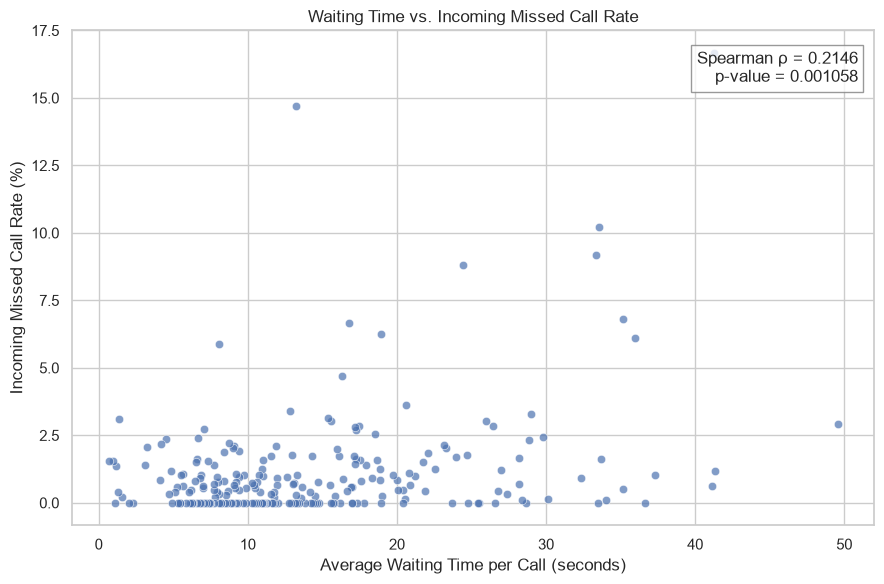

In [80]:
sns.set_theme(style='whitegrid')

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=incoming_test_data,
    x='weighted_avg_wait_per_call',
    y='missed_call_rate',
    alpha=0.7
)

plt.xlabel('Average Waiting Time per Call (seconds)')
plt.ylabel('Incoming Missed Call Rate (%)')
plt.title(
    'Waiting Time vs. Incoming Missed Call Rate'
)

plt.text(
    0.98, 0.96,
    'Spearman ρ = 0.2146\np-value = 0.001058',
    transform=plt.gca().transAxes,
    ha='right',
    va='top',
    bbox=dict(
        facecolor='white',
        alpha=0.8,
        edgecolor='gray'
    )
)

plt.tight_layout()
plt.show()

- Foi investigado se existe uma associacao entre a espera media ponderada por chamada recebida nao perdida e a taxa de chamadas recebidas perdidas por operador. Foram considerados 230 operadores que possuiam pelo menos 50 chamadas recebidas nao perdidas. 
---
Hipóteses: 

- **H₀:** nao existe associacao entre o tempo medio de espera por chamada e a taxa de chamadas recebidas perdidas.
- **H₁:** existe associacao entre essas metricas.
Foi adotado o nivel de significancia de 5% (α = 0,05).
--- 
- Foi utilizado o teste de correlacao de Spearman, apropriado para avaliar associacoes monotonicas sem exigir distribuição normal das variaveis.

| Indicador | Resultado |
|---|---:|
| Operadores analisados | 230 |
| Correlação de Spearman (ρ) | 0,2146 |
| Valor-p | 0,001058 |
| Nível de significância | 0,05 |

---
- A correlacao de Spearman foi positiva e fraca (ρ = 0,2146). Isso indica que valores maiores de espera media tendem a acompanhar taxas maiores de chamadas recebidas perdidas, embora a associacao observada seja limitada. Como o valor-p foi inferior a 0,05, rejeitou-se a hipotese nula. Portanto, foram encontradas evidencias estatisticas de uma associação entre as metricas na amostra analisada.
- A analise foi realizada no nível do operador, utilizando metricas agregadas, e incluiu apenas operadores com pelo menos 50 chamadas recebidas nao perdidas.

In [81]:
incoming_group_comparison = incoming_test_data.copy()

median_missed_rate = (
    incoming_group_comparison['missed_call_rate'].median()
)

incoming_group_comparison['missed_rate_group'] = (
    incoming_group_comparison['missed_call_rate'].apply(
        lambda rate: (
            'Above median'
            if rate > median_missed_rate
            else 'At or below median'
        )
    )
)

print(f'Median missed call rate: {median_missed_rate:.4f}%')

Median missed call rate: 0.6026%


In [82]:
group_wait_summary = (
    incoming_group_comparison
    .groupby('missed_rate_group')
    .agg(
        operators=('weighted_avg_wait_per_call', 'size'),
        median_wait=('weighted_avg_wait_per_call', 'median'),
        mean_wait=('weighted_avg_wait_per_call', 'mean'),
        p90_wait=(
            'weighted_avg_wait_per_call',
            lambda values: values.quantile(0.90)
        ),
        median_missed_rate=('missed_call_rate', 'median')
    )
)

group_wait_summary

,operators,median_wait,mean_wait,p90_wait,median_missed_rate
missed_rate_group,,,,,
Above median,115,14.333333,15.975177,29.479171,1.530612
At or below median,115,11.088496,13.016683,25.199185,0.000000


In [83]:
wait_above_median = incoming_group_comparison.loc[
    incoming_group_comparison['missed_rate_group'] == 'Above median',
    'weighted_avg_wait_per_call'
]

wait_at_or_below_median = incoming_group_comparison.loc[
    incoming_group_comparison['missed_rate_group'] == 'At or below median',
    'weighted_avg_wait_per_call'
]

mann_whitney_result = mannwhitneyu(
    wait_above_median,
    wait_at_or_below_median,
    alternative='two-sided'
)

print(f'U statistic: {mann_whitney_result.statistic:.2f}')
print(f'p-value: {mann_whitney_result.pvalue:.6f}')

U statistic: 7711.00
p-value: 0.029544


- Foi investigado se existe diferenca nas distribuicoes dos tempos medios de espera por chamada recebida nao perdida entre operadores com taxas de chamadas recebidas perdidas acima da mediana e operadores com taxas iguais ou abaixo dela. A divisao foi realizada utilizando a mediana da taxa de chamadas recebidas perdidas, aproximadamente `0,6026%`. Cada grupo contem 115 operadores. 
---
- **H₀:** as distribuicoes dos tempos medios de espera são iguais entre os dois grupos.
- **H₁:** as distribuicoes dos tempos medios de espera são diferentes entre os dois grupos.
- Foi adotado o nível de significância de 5% (α = 0,05), com um teste bilateral.
---
- Foi aplicado o teste de Mann–Whitney, utilizado para comparar duas amostras independentes.

| Indicador | Resultado |
|---|---:|
| Operadores no grupo acima da mediana | 115 |
| Operadores no grupo igual ou abaixo da mediana | 115 |
| Estatistica U | 7.711 |
| Valor-p | 0,029544 |
| Nivel de significancia | 0,05 |

--- 
- Comparacao descritiva: 

| Métrica | Taxa acima da mediana | Taxa igual ou abaixo da mediana |
|---|---:|---:|
| Mediana da espera media | 14,33 segundos | 11,09 segundos |
| Media da espera media | 15,98 segundos | 13,02 segundos |
| Percentil 90 da espera media | 29,48 segundos | 25,20 segundos |

- O grupo com taxa de chamadas recebidas perdidas acima da mediana apresentou valores mais elevados nas tres estatisticas descritivas.
---
- O teste de Mann–Whitney identificou uma diferençca estatisticamente significativa entre as distribuicoes dos tempos medios de espera dos dois grupos (U = 7.711; p = 0,029544). Os resultados são compativeis com a associacao positiva fraca identificada pelo teste de Spearman. Em conjunto, as analises sugerem que o tempo de espera esta associado a taxa de chamadas recebidas perdidas, mas nao estabelecem uma relacao causal nem justificam classificar operadores individualmente como ineficientes.

In [84]:
n_above = len(wait_above_median)
n_at_or_below_median = len(wait_at_or_below_median)

u_statistic = mann_whitney_result.statistic

rank_biserial = (
    (2 * u_statistic) / (n_above * n_at_or_below_median)
) - 1

median_difference = (
    wait_above_median.median()
    - wait_at_or_below_median.median()
)

print(f'Rank-biserial correlation: {rank_biserial:.4f}')
print(f'Difference between medians: {median_difference:.2f} seconds')

Rank-biserial correlation: 0.1661
Difference between medians: 3.24 seconds


- Complementar o teste de Mann–Whitney por meio de uma medida de tamanho do efeito, avaliando a magnitude da diferenca observada entre os tempos medios de espera dos dois grupos de operadores. 

| Indicador | Resultado |
|---|---:|
| Correlação bisserial por postos | 0,1661 |
| Diferença entre as medianas | 3,24 segundos |
| Valor-p do teste de Mann–Whitney | 0,029544 |
| Nível de significância | 0,05 |

--- 
- A correlacao bisserial por postos foi positiva e de pequena magnitude. Isso indica que os tempos de espera tendem a ser maiores no grupo de operadores com taxas de chamadas recebidas perdidas acima da mediana, embora exista sobreposicao consideravel entre as distribuicoes.
- A mediana do tempo de espera foi aproximadamente `3,24 segundos` maior nesse grupo, comparada ao grupo com taxas iguais ou abaixo da mediana.
- O teste de Mann–Whitney identificou uma diferenca estatisticamente significativa entre as distribuicoes (p = 0,029544). Entretanto, o tamanho do efeito e pequeno, indicando que a diferenca deve ser interpretada com cautela em termos de relevancia operacional.

In [85]:
outgoing_incoming_test = outgoing_all_operator_metrics[
    ['active_outgoing_calls']
].join(
    operator_metrics[
        [
            'incoming_calls',
            'missed_calls',
            'missed_call_rate'
        ]
    ],
    how='inner'
)

outgoing_incoming_test = outgoing_incoming_test.dropna(
    subset=[
        'active_outgoing_calls',
        'missed_call_rate'
    ]
)

print(
    'Operators included in the analysis:',
    len(outgoing_incoming_test)
)

outgoing_incoming_test[
    [
        'active_outgoing_calls',
        'missed_call_rate'
    ]
].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90]
)

Operators included in the analysis: 544


,active_outgoing_calls,missed_call_rate
count,544.000000,544.000000
mean,383.034926,1.822811
std,2202.069228,6.835318
min,0.000000,0.000000
25%,7.000000,0.000000
50%,58.000000,0.000000
75%,271.750000,0.892953
90%,743.500000,3.856209
max,35196.000000,100.000000


In [86]:
outgoing_spearman = spearmanr(
    outgoing_incoming_test['active_outgoing_calls'],
    outgoing_incoming_test['missed_call_rate']
)

print(
    f"Spearman correlation: "
    f"{outgoing_spearman.statistic:.4f}"
)

print(
    f"p-value: "
    f"{outgoing_spearman.pvalue:.3e}"
)

Spearman correlation: 0.2378
p-value: 1.971e-08


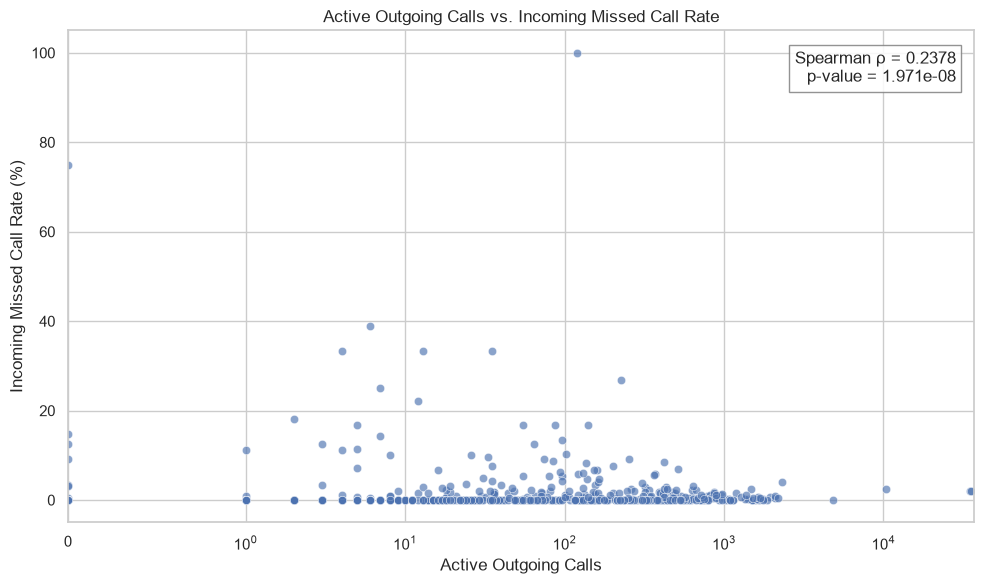

In [87]:
sns.set_theme(style='whitegrid')

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=outgoing_incoming_test,
    x='active_outgoing_calls',
    y='missed_call_rate',
    alpha=0.65
)

plt.xscale('symlog', linthresh=1)
plt.xlim(left=0)

plt.xlabel('Active Outgoing Calls')
plt.ylabel('Incoming Missed Call Rate (%)')
plt.title('Active Outgoing Calls vs. Incoming Missed Call Rate')

plt.text(
    0.98, 0.96,
    f"Spearman ρ = {outgoing_spearman.statistic:.4f}\n"
    f"p-value = {outgoing_spearman.pvalue:.3e}",
    transform=plt.gca().transAxes,
    ha='right',
    va='top',
    bbox=dict(
        facecolor='white',
        alpha=0.85,
        edgecolor='gray'
    )
)

plt.tight_layout()
plt.show()

- Foi investigado se existe uma associacao entre o volume de chamadas de saida nao perdidas e a taxa de chamadas recebidas perdidas por operador. Foram analisados 544 operadores que possuiam ambas as metricas disponiveis. 
--- 
- **H₀:** nao existe associacao entre o volume de chamadas de saida nao perdidas e a taxa de chamadas recebidas perdidas.
- **H₁:** existe uma associacao entre essas metricas.
- Foi adotado o nivel de significancia de 5% (α = 0,05).
---
- Foi utilizado o teste de correlacao de Spearman, adequado para investigar associacoes monotonicas sem exigir distribuicao normal das variaveis.

| Indicador | Resultado |
|---|---:|
| Operadores analisados | 544 |
| Correlação de Spearman (ρ) | 0,2378 |
| Valor-p | Inferior a 0,001 |
| Nível de significância | 0,05 |

--- 
- Foi identificada uma associacao positiva fraca entre o volume de chamadas de saida nao perdidas e a taxa de chamadas recebidas perdidas. O valor-p foi inferior ao nivel de significancia de 0,05. Portanto, rejeitou-se a hipotese nula e foram encontradas evidencias estatisticas de uma associacao entre as metricas na amostra analisada. O resultado indica que operadores com maior volume de chamadas de saida nao perdidas tendem a apresentar taxas maiores de chamadas recebidas perdidas. Entretanto, a associação e fraca e não demonstra uma relacao causal.


In [88]:
thresholds = [None, 10, 20, 50, 100]

sensitivity_results = []

for threshold in thresholds:

    if threshold is None:
        subset = outgoing_incoming_test.copy()
        label = 'No minimum'
    else:
        subset = outgoing_incoming_test[
            outgoing_incoming_test['incoming_calls'] >= threshold
        ].copy()
        label = threshold

    # Calcular Spearman se houver dados suficientes
    if len(subset) >= 3:
        result = spearmanr(
            subset['active_outgoing_calls'],
            subset['missed_call_rate']
        )

        rho = result.statistic
        p_value = result.pvalue
    else:
        rho = float('nan')
        p_value = float('nan')

    sensitivity_results.append({
        'minimum_incoming_calls': label,
        'operators': len(subset),
        'spearman_rho': rho,
        'p_value': p_value
    })

sensitivity_summary = pd.DataFrame(sensitivity_results)

sensitivity_summary

,minimum_incoming_calls,operators,spearman_rho,p_value
0,No minimum,544,0.237805,1.971399e-08
1,10,355,0.050570,3.420788e-01
2,20,290,0.012194,8.361879e-01
3,50,205,-0.078852,2.610814e-01
4,100,154,-0.046291,5.686206e-01


- O objetivo foi verificar se a associacao observada entre o volume de chamadas de saida nao perdidas e a taxa de chamadas recebidas perdidas permanece semelhante quando sao considerados diferentes volumes minimos de chamadas recebidas por operador. 

| Minimo de chamadas recebidas | Operadores analisados | Correlacao de Spearman (ρ) | Valor-p |
|---:|---:|---:|---:|
| Sem limite | 544 | 0,2378 | 1,971 × 10⁻⁸ |
| 10 | 355 | 0,0506 | 0,3421 |
| 20 | 290 | 0,0122 | 0,8362 |
| 50 | 205 | −0,0789 | 0,2611 |
| 100 | 154 | −0,0463 | 0,5686 |

--- 
- Na amostra completa, foi observada uma associacao positiva fraca entre as metricas, estatisticamente significativa. Entretanto, ao considerar apenas operadores com pelo menos dez chamadas recebidas, a correlacao diminuiu consideravelmente e deixou de apresentar significancia estatistica. 

In [89]:
low_volume_operators = outgoing_incoming_test[
    outgoing_incoming_test['incoming_calls'] < 10
]

higher_volume_operators = outgoing_incoming_test[
    outgoing_incoming_test['incoming_calls'] >= 10
]

for label, group in [
    ('Fewer than 10 incoming calls', low_volume_operators),
    ('At least 10 incoming calls', higher_volume_operators)
]:
    result = spearmanr(
        group['active_outgoing_calls'],
        group['missed_call_rate']
    )

    print(f'\n{label}')
    print(f'Operators: {len(group)}')
    print(f'Spearman correlation: {result.statistic:.4f}')
    print(f'p-value: {result.pvalue:.6g}')


Fewer than 10 incoming calls
Operators: 189
Spearman correlation: -0.0284
p-value: 0.698106

At least 10 incoming calls
Operators: 355
Spearman correlation: 0.0506
p-value: 0.342079


- Para investigar a sensibilidade da correlacao inicial, os operadores foram separados em dois grupos: aqueles com menos de 10 chamadas recebidas e aqueles com pelo menos 10 chamadas recebidas.

| Grupo | Operadores | Correlacao de Spearman (ρ) | Valor-p |
|---|---:|---:|---:|
| Menos de 10 chamadas recebidas | 189 | -0,0284 | 0,698106 |
| Pelo menos 10 chamadas recebidas | 355 | 0,0506 | 0,342079 |
---
- Nenhum dos grupos apresentou uma associacao estatisticamente significativa ao nivel de 5%. Na amostra completa, havia sido observada uma correlacao positiva fraca e estatisticamente significativa (ρ = 0,2378; p < 0,001). Entretanto, esse resultado nao se manteve quando os operadores foram analisados separadamente segundo o volume de chamadas recebidas.
- Essa diferenca sugere que a associacao inicial e sensível a composição da amostra. Taxas calculadas sobre volumes pequenos podem apresentar maior variabilidade, mas os resultados disponiveis nao permitem afirmar que essa seja a unica explicacao.



In [90]:
incoming_volume_comparison = outgoing_incoming_test.assign(
    incoming_volume_group=lambda df: df['incoming_calls'].apply(
        lambda value: (
            'Fewer than 10'
            if value < 10
            else '10 or more'
        )
    )
)

incoming_volume_summary = (
    incoming_volume_comparison
    .groupby('incoming_volume_group')
    .agg(
        operators=('active_outgoing_calls', 'size'),
        median_incoming_calls=('incoming_calls', 'median'),
        median_active_outgoing=(
            'active_outgoing_calls', 'median'
        ),
        median_missed_rate=('missed_call_rate', 'median'),
        mean_missed_rate=('missed_call_rate', 'mean')
    )
)

incoming_volume_summary

,operators,median_incoming_calls,median_active_outgoing,median_missed_rate,mean_missed_rate
incoming_volume_group,,,,,
10 or more,355,65.0,131.0,0.225861,1.653650
Fewer than 10,189,3.0,8.0,0.000000,2.140548


- Para complementar a analise de sensibilidade, os 544 operadores foram divididos em dois grupos: operadores com menos de 10 chamadas recebidas e operadores com pelo menos 10 chamadas recebidas.

| Metrica | Menos de 10 chamadas recebidas | 10 ou mais chamadas recebidas |
|---|---:|---:|
| Operadores | 189 | 355 |
| Mediana de chamadas recebidas | 3 | 65 |
| Mediana de chamadas de saída não perdidas | 8 | 131 |
| Mediana da taxa de chamadas recebidas perdidas | 0,00% | 0,23% |
| Média da taxa de chamadas recebidas perdidas | 2,14% | 1,65% |
---
- O grupo com menor volume de chamadas recebidas apresentou uma mediana de atividade de saida mais baixa. Alem disso, nesse grupo, a media da taxa de chamadas perdidas foi superior a mediana, indicando uma distribuicao assimetrica, possivelmente influenciada por alguns operadores com taxas elevadas. Entretanto, os testes de Spearman realizados separadamente nos dois grupos nao identificaram associacoes estatisticamente significativas entre o volume de chamadas de saida nao perdidas e a taxa de chamadas recebidas perdidas.


In [91]:

statistical_results = pd.DataFrame([
    {
        'analysis': 'Waiting time vs. incoming missed-call rate',
        'operators': 230,
        'test': 'Spearman',
        'statistic': 0.2146,
        'p_value': 0.001058,
        'conclusion': 'Weak positive association; significant'
    },
    {
        'analysis': 'Waiting time: groups above/below median missed rate',
        'operators': 230,
        'test': 'Mann-Whitney',
        'statistic': 7711.00,
        'p_value': 0.029544,
        'conclusion': 'Significant difference; small effect'
    },
    {
        'analysis': 'Outgoing active calls vs. incoming missed-call rate',
        'operators': 544,
        'test': 'Spearman',
        'statistic': 0.237805,
        'p_value': 1.971399e-08,
        'conclusion': 'Weak positive association in full sample'
    },
    {
        'analysis': 'Outgoing active calls vs. missed rate (incoming >= 10)',
        'operators': 355,
        'test': 'Spearman',
        'statistic': 0.050570,
        'p_value': 0.342079,
        'conclusion': 'No significant association detected'
    },
    {
        'analysis': 'Outgoing active calls vs. missed rate (incoming >= 20)',
        'operators': 290,
        'test': 'Spearman',
        'statistic': 0.012194,
        'p_value': 0.836188,
        'conclusion': 'No significant association detected'
    },
    {
        'analysis': 'Outgoing active calls vs. missed rate (incoming >= 50)',
        'operators': 205,
        'test': 'Spearman',
        'statistic': -0.078852,
        'p_value': 0.261081,
        'conclusion': 'No significant association detected'
    },
    {
        'analysis': 'Outgoing active calls vs. missed rate (incoming >= 100)',
        'operators': 154,
        'test': 'Spearman',
        'statistic': -0.046291,
        'p_value': 0.568621,
        'conclusion': 'No significant association detected'
    }
])

statistical_results

,analysis,operators,test,statistic,p_value,conclusion
0,Waiting time vs. incoming missed-call rate,230,Spearman,0.214600,1.058000e-03,Weak positive association; significant
1,Waiting time: groups above/below median missed...,230,Mann-Whitney,7711.000000,2.954400e-02,Significant difference; small effect
2,Outgoing active calls vs. incoming missed-call...,544,Spearman,0.237805,1.971399e-08,Weak positive association in full sample
3,Outgoing active calls vs. missed rate (incomin...,355,Spearman,0.050570,3.420790e-01,No significant association detected
4,Outgoing active calls vs. missed rate (incomin...,290,Spearman,0.012194,8.361880e-01,No significant association detected
5,Outgoing active calls vs. missed rate (incomin...,205,Spearman,-0.078852,2.610810e-01,No significant association detected
6,Outgoing active calls vs. missed rate (incomin...,154,Spearman,-0.046291,5.686210e-01,No significant association detected


In [92]:
incoming_summary = operator_metrics.rename(
    columns={
        'incoming_calls': 'incoming_calls_total',
        'missed_calls': 'incoming_missed_calls',
        'missed_call_rate': 'incoming_missed_rate_pct'
    }
)[[
    'incoming_calls_total',
    'incoming_missed_calls',
    'incoming_missed_rate_pct'
]]

wait_summary_operator = operator_wait_metrics[[
    'register_total',
    'calls_total',
    'total_wait_time',
    'weighted_avg_wait_per_call'
]].rename(
    columns={
        'register_total': 'incoming_answered_registers',
        'calls_total': 'incoming_answered_calls',
        'total_wait_time': 'incoming_total_wait_time',
        'weighted_avg_wait_per_call': 'incoming_avg_wait_per_call'
    }
)

outgoing_summary = outgoing_operator_review[[
    'outgoing_registers',
    'all_outgoing_calls',
    'active_outgoing_calls',
    'missed_outgoing_calls'
]].copy()

outgoing_summary['missed_outgoing_rate_pct'] = (
    outgoing_summary['missed_outgoing_calls']
    .div(
        outgoing_summary['all_outgoing_calls'].where(
            outgoing_summary['all_outgoing_calls'] > 0
        )
    )
    * 100
)

operator_performance = (
    incoming_summary
    .join(wait_summary_operator, how='outer')
    .join(outgoing_summary, how='outer')
    .sort_index()
)
 
print('Total number of operators in the table:', len(operator_performance))

operator_performance.head(10)

Total number of operators in the table: 1092


,incoming_calls_total,incoming_missed_calls,incoming_missed_rate_pct,incoming_answered_registers,incoming_answered_calls,incoming_total_wait_time,incoming_avg_wait_per_call,outgoing_registers,all_outgoing_calls,active_outgoing_calls,missed_outgoing_calls,missed_outgoing_rate_pct
operator_id,,,,,,,,,,,,
879896,58.0,0.0,0.0,21.0,58.0,574.0,9.896552,96.0,872.0,621.0,251.0,28.784404
879898,104.0,0.0,0.0,57.0,104.0,1680.0,16.153846,170.0,7209.0,4849.0,2360.0,32.736857
880020,7.0,0.0,0.0,7.0,7.0,54.0,7.714286,13.0,38.0,16.0,22.0,57.894737
880022,8.0,0.0,0.0,8.0,8.0,112.0,14.000000,62.0,189.0,84.0,105.0,55.555556
880026,24.0,0.0,0.0,18.0,24.0,143.0,5.958333,164.0,2208.0,1560.0,648.0,29.347826
880028,63.0,0.0,0.0,41.0,63.0,343.0,5.444444,161.0,2497.0,1504.0,993.0,39.767721
880240,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.0,47.0,30.0,17.0,36.170213
881278,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.0,20.0,3.0,17.0,85.000000
882476,3.0,0.0,0.0,3.0,3.0,95.0,31.666667,NaN,NaN,NaN,NaN,NaN


In [93]:
metrics_to_check = [
    'incoming_missed_rate_pct',
    'incoming_avg_wait_per_call',
    'active_outgoing_calls',
    'missed_outgoing_rate_pct'
]

metric_coverage = pd.DataFrame({
    'metric': metrics_to_check,
    'operators_with_data': [
        operator_performance[column].notna().sum()
        for column in metrics_to_check
    ]
})

metric_coverage['coverage_pct'] = (
    metric_coverage['operators_with_data']
    / len(operator_performance)
    * 100
)

metric_coverage

,metric,operators_with_data,coverage_pct
0,incoming_missed_rate_pct,754,69.047619
1,incoming_avg_wait_per_call,753,68.956044
2,active_outgoing_calls,882,80.769231
3,missed_outgoing_rate_pct,882,80.769231


In [94]:

incoming_rate_eligible = operator_metrics[
    operator_metrics['incoming_calls'] >= 50
].copy()


p95_incoming_missed_rate = (
    incoming_rate_eligible['missed_call_rate'].quantile(0.95)
)

print(
    'Operators eligible for incoming missed-rate analysis:',
    len(incoming_rate_eligible)
)

print(
    f'95th percentile of incoming missed-call rate: '
    f'{p95_incoming_missed_rate:.2f}%'
)

print(
    'Operators above the 95th percentile:',
    (
        incoming_rate_eligible['missed_call_rate']
        > p95_incoming_missed_rate
    ).sum()
)

Operators eligible for incoming missed-rate analysis: 234
95th percentile of incoming missed-call rate: 4.25%
Operators above the 95th percentile: 12


In [95]:
priority_flags = pd.DataFrame(index=operator_performance.index)

for column in [
    'high_wait',
    'high_incoming_missed_rate',
    'low_active_outgoing'
]:
    priority_flags[column] = pd.Series(
        pd.NA,
        index=priority_flags.index,
        dtype='boolean'
    )


priority_flags.loc[
    operator_wait_50.index,
    'high_wait'
] = (
    operator_wait_50['weighted_avg_wait_per_call'] > p95_wait
).astype('boolean')


priority_flags.loc[
    incoming_rate_eligible.index,
    'high_incoming_missed_rate'
] = (
    incoming_rate_eligible['missed_call_rate']
    > p95_incoming_missed_rate
).astype('boolean')


outgoing_eligible = outgoing_operator_review[
    outgoing_operator_review['all_outgoing_calls'] >= 50
]

priority_flags.loc[
    outgoing_eligible.index,
    'low_active_outgoing'
] = (
    outgoing_eligible['active_outgoing_calls'] < 50
).astype('boolean')


priority_flags['signals_count'] = (
    priority_flags[
        [
            'high_wait',
            'high_incoming_missed_rate',
            'low_active_outgoing'
        ]
    ]
    .fillna(False)
    .astype(int)
    .sum(axis=1)
)


priority_flags['signals_evaluated'] = (
    priority_flags[
        [
            'high_wait',
            'high_incoming_missed_rate',
            'low_active_outgoing'
        ]
    ]
    .notna()
    .sum(axis=1)
)

priority_flags.head()

,high_wait,high_incoming_missed_rate,low_active_outgoing,signals_count,signals_evaluated
operator_id,,,,,
879896,False,False,False,0,3
879898,False,False,False,0,3
880020,<NA>,<NA>,<NA>,0,0
880022,<NA>,<NA>,False,0,1
880026,<NA>,<NA>,False,0,1


In [96]:
evaluated_operators = priority_flags[
    priority_flags['signals_evaluated'] > 0
].copy()

signals_summary = (
    evaluated_operators['signals_count']
    .value_counts()
    .reindex([0, 1, 2, 3], fill_value=0)
    .rename_axis('number_of_positive_signals')
    .reset_index(name='operators')
)

signals_summary

,number_of_positive_signals,operators
0,0,490
1,1,70
2,2,5
3,3,0


In [97]:

priority_cases = priority_flags[
    priority_flags['signals_count'] >= 2
].join(
    operator_performance,
    how='left'
)


priority_cases[
    [
        'high_wait',
        'high_incoming_missed_rate',
        'low_active_outgoing',
        'signals_count',
        'signals_evaluated',
        'incoming_calls_total',
        'incoming_missed_rate_pct',
        'incoming_avg_wait_per_call',
        'all_outgoing_calls',
        'active_outgoing_calls'
    ]
].sort_values(
    'signals_count',
    ascending=False
)

,high_wait,high_incoming_missed_rate,low_active_outgoing,signals_count,signals_evaluated,incoming_calls_total,incoming_missed_rate_pct,incoming_avg_wait_per_call,all_outgoing_calls,active_outgoing_calls
operator_id,,,,,,,,,,
906070,True,False,True,2,3,324.0,0.617284,41.114907,71.0,32.0
944216,True,True,False,2,3,235.0,10.212766,33.559242,133.0,102.0
944218,True,True,False,2,3,245.0,6.122449,35.934783,164.0,130.0
944220,True,True,False,2,3,265.0,6.792453,35.129555,221.0,153.0
944226,True,True,False,2,3,180.0,16.666667,41.253333,109.0,87.0


- O objetivo era consolidar os tres sinais exploratorios utilizados para identificar operadores que merecem investigacao adicional:
    - Espera media por chamada recebida nao perdida acima do percentil 95.
    - Taxa de chamadas recebidas perdidas acima do percentil 95.
    - Menos de 50 chamadas de saida não perdidas, considerando operadores com pelo menos 50 chamadas de saida no total.
---
- Foram identificados cinco operadores com dois sinais positivos entre os indicadores que puderam ser avaliados.

| Operador | Espera media por chamada | Taxa de chamadas recebidas perdidas | Chamadas de saida não perdidas | Sinais positivos |
|---:|---:|---:|---:|---:|
| 944226 | 41,25 segundos | 16,67% | 87 | 2 |
| 944216 | 33,56 segundos | 10,21% | 102 | 2 |
| 944220 | 35,13 segundos | 6,79% | 153 | 2 |
| 944218 | 35,93 segundos | 6,12% | 130 | 2 |
| 906070 | 41,11 segundos | 0,62% | 32 | 2 |

- Os operadores 944226, 944216, 944220 e 944218 apresentaram simultaneamente espera media elevada e taxa elevada de chamadas recebidas perdidas. O operador 906070 apresentou espera media elevada e baixo volume de chamadas de saida não perdidas, mas não apresentou taxa elevada de chamadas recebidas perdidas segundo o criterio utilizado.
---
- A analise integrada permitiu identificar diferentes combinacoes de sinais. Quatro operadores se destacaram pela combinacao de espera elevada e taxa elevada de chamadas recebidas perdidas. Outro se destacou pela combinacao de espera elevada e baixo volume de chamadas de saida nao perdidas. Nenhum operador apresentou os tres sinais simultaneamente.
- A ausencia de `operator_id` em muitos registros de chamadas perdidas limita a interpretacao das taxas individuais. Os indicadores tambem não demonstram causalidade.


In [98]:
priority_dashboard = (
    priority_flags[
        priority_flags['signals_count'] >= 2 
    ].join(operator_performance, how='left')
    .copy()
)

priority_dashboard = priority_dashboard.sort_values(
    ['incoming_missed_rate_pct', 'incoming_avg_wait_per_call'],
    ascending=False
)

priority_dashboard = priority_dashboard[
    [
         'signals_count',
        'signals_evaluated',
        'high_wait',
        'incoming_avg_wait_per_call',
        'high_incoming_missed_rate',
        'incoming_missed_rate_pct',
        'incoming_calls_total',
        'low_active_outgoing',
        'active_outgoing_calls',
        'all_outgoing_calls',
        'missed_outgoing_rate_pct'
    ]
].rename(columns={
    'signals_count': 'positive_signals',
    'signals_evaluated': 'evaluated_signals',
    'high_wait': 'high_wait_signal',
    'incoming_avg_wait_per_call': 'avg_incoming_wait_sec',
    'high_incoming_missed_rate': 'high_incoming_missed_signal',
    'incoming_missed_rate_pct': 'incoming_missed_rate_pct',
    'incoming_calls_total': 'incoming_calls',
    'low_active_outgoing': 'low_outgoing_signal',
    'active_outgoing_calls': 'active_outgoing_calls',
    'all_outgoing_calls': 'all_outgoing_calls',
    'missed_outgoing_rate_pct': 'outgoing_missed_rate_pct'
})

for column in [
    'high_wait_signal',
    'high_incoming_missed_signal',
    'low_outgoing_signal'
]:
    priority_dashboard[column] = (
        priority_dashboard[column]
        .map({True: 'Yes', False: 'No'})
        .fillna('Not evaluated')
    )

priority_dashboard

,positive_signals,evaluated_signals,high_wait_signal,avg_incoming_wait_sec,high_incoming_missed_signal,incoming_missed_rate_pct,incoming_calls,low_outgoing_signal,active_outgoing_calls,all_outgoing_calls,outgoing_missed_rate_pct
operator_id,,,,,,,,,,,
944226,2,3,Yes,41.253333,Yes,16.666667,180.0,No,87.0,109.0,20.183486
944216,2,3,Yes,33.559242,Yes,10.212766,235.0,No,102.0,133.0,23.308271
944220,2,3,Yes,35.129555,Yes,6.792453,265.0,No,153.0,221.0,30.769231
944218,2,3,Yes,35.934783,Yes,6.122449,245.0,No,130.0,164.0,20.731707
906070,2,3,Yes,41.114907,No,0.617284,324.0,Yes,32.0,71.0,54.929577


# Conclusao Geral 

O objetivo deste projeto foi analisar os dados de chamadas da CallMeMaybe para identificar operadores com possiveis sinais de ineficiencia, considerando o volume de chamadas recebidas perdidas, o tempo de espera e o volume de chamadas de saida nao perdidas. 

A base original de chamadas continha 53.902 registros. Foram identificados 4.900 registros duplicados exatos e criada uma base de analise com 49.002 registros, apos a remocao dessas duplicatas. Como os dados nao possuem um identificador unico de chamada, nao foi possivel confirmar se todos os registros duplicados eram erros de ingestao. 

Tambem foram identificados 8.172 valores ausentes em `operator_id`, correspondestes a 15,16% da base original. A ausencia desse identificador concentrou-se principamente nas chamadas recebidas perdidas. 

Entre os 230 operadores elegiveis para a analise de espera, 12 apresentam media ponderada de espera por chamada superior ao percentil 95, cujo valor foi de 33,54 segundos. 

Na analise da taxa de chamadas recebidas perdidas, considerando operadores com pelo menos 50 chamadas recebidas, o percentil 95 foi de 4,25%. Do total de 234 operadores elegiveis, 12 ficaram acima do limite. Os resultados indicam que existem operadores com valores elevados nesses indicadores. Entretanto, a espera media e a taxa de chamadas perdidas nao apontam necessariamente para os mesmos operadores. 

O teste de Spearman identificou uma associacao positiva fraca entre o tempo medio de espera e a taxa de chamadas recebidas perdidas ((\rho = 0,2146); valor-p = 0,001058). O resultado e estatisticamente significativo, mas a magnitude da associacao e pequena. 

O teste de Mann-Whitney tambem identificou uma diferenca estatisticamente significativa entre as distribuicoes do tempo medio de espera dos grupos de operadores definidos pela mediana da taxa de chamadas recebidas perdidas (valor-p = 0,029544). A diferenca entre as medianas foi de aproximadamente 3,24 segundos, com tamanho de efeito pequeno. 

Na analise de relacao entre chamadas de saida nao perdidas e taxa de chamadas recebidas perdidas, foi observada uma associacao positiva fraca na amostra completa de 544 operadores ((\rho = 0,2378); valor-p = 1,97 × 10⁻⁸). Contudo, essa associacao deixou de ser estatisticamente significativa quando a analise foi restringida a operadores com pelo menos 10, 20, 50 ou 100 chamadas recebidas. 

### Identificacao de operadores prioritarios

Para consolidar os resultados, foram utilizados tres sinais exploratorios: 

- Tempo medio de espera por chamada recebida nao perdida acima do percentil 95.
- Taxa de chamadas recebidas perdidas acima do percentil 95, entre operadores com pelo menos 50 chamadas recebidas.
- Menos de 50 chamadas de saida não perdidas, entre operadores com pelo menos 50 chamadas de saida no total.

Os resultados identificaram cinco operadores com pelo menos dois sinais positivos: 

- 944226: espera media de 41,25 segundos e taxa de chamadas recebidas perdidas de 16,67%.
- 944216: espera media de 33,56 segundos e taxa de chamadas recebidas perdidas de 10,21%.
- 944220: espera media de 35,13 segundos e taxa de chamadas recebidas perdidas de 6,79%.
- 944218: espera media de 35,93 segundos e taxa de chamadas recebidas perdidas de 6,12%.
- 906070: espera media de 41,11 segundos e 32 chamadas de saida nao perdidas, em um total de 71 chamadas de saida.

Os quatros primeiros operadores apresentaram simultaneamente espera elevada e taxa elevada de chamadas recebidas perdidas. O operador 906070 apresentou espera elevada e baixo volume de chamadas de saida nao perdidas, mas nao apresentou taxa elevada de chamadas recebidas perdidas. 

A analise permitiu estabelecer criterios mensuraveis para identificar operadores que merecem uma investigacao mais detalhada. Os cincos operadores selecionados constituem uma lista inicial de prioridade para os supervisores da CallMeMaybe. Entretanto, os resultados nao comprovam, isoladamente, que esses operadores seja ineficientes. 

Recomenda-se que os supervisores investiguem os casos prioritarios, verificando a distribuicao das chamadas, o encaminhamento entre operadores, a carga de trabalho e as responsabilidades de cada funcao. Tambem e importante avaliar a origem dos registros sem `operator_id`, para melhor a confiabilidade das futuras avaliacoes de desempenho. 